# DTD ablation 04: both_fusion, ViT-L/16

Only `both_fusion` is trained: query image + query caption + one selected context image + that
context image's caption. Both text-fusion gates are enabled; the selector uses image features only.
There is no text similarity in candidate selection. The selected image index also gathers its
aligned caption vector. Candidate labels are never classifier/selector inputs.

The architecture, classifier head, visual selector, losses, augmentations and optimizer settings
are unchanged from notebooks 01/02/03. Defaults: official DTD split 1, seed 42, 50 epochs with a
50-epoch LR schedule, no early stopping, best checkpoint selected by validation loss. Each split
has 1,880 images. The fixed pool contains 376 training images; a query cannot select itself.
Validation/test images and their captions never become candidates. Their own image-derived query
captions are available for classification, using the same image-only caption pipeline as training.

CAPTION_INPUT_POLICY defaults to `dtd_lexical_v2`, matching the updated notebooks 02/03. Generic
openings are removed before retaining 5-8 words from raw_caption. Direct DTD class names are
screened; CLIP audit scores are diagnostic, not a hard gate or a calibrated leak probability.
Legacy scores are marked when they refer to text before cleanup. This does not prove absence of
synonyms/implicit class information. `legacy_strict` is an explicit alternative experiment, not
interchangeable with the default policy. Do not mix policies when comparing ablation scores.

Attach DTD, local DINOv3 code/ViT-L weights and CLIP ViT-B/32. This notebook reuses a complete
audited DTD captions.csv from notebooks 02/03 when available. Otherwise it creates/resumes the CSV
with local Florence-2, flushing each finished batch. Caption generation sees image pixels only,
never per-image labels or filenames. Attach `/kaggle/input/notebooks/nguyenducxu/notebook-mt-moi`
with Florence-2-base and compatible offline wheels if generation is needed. Legacy Florence runs
in an isolated subprocess; all dependencies/models stay offline and the kernel is not downgraded.
Use CAPTIONS_INPUT_PATH, FLORENCE_MODEL_REF and OFFLINE_ASSETS_ROOT for different attached paths.

The original CSV is preserved. shared/caption_model_inputs.csv records actual text and masks;
CLIP caches vectors for those texts. Candidate vectors are gathered only from the training pool.
Invalid captions mask their own text gate to zero independently; valid text in the other role
remains usable. All-invalid query/pool branches stop before training rather than silently changing
the intended ablation. Coverage for each role is exported in shared/caption_role_coverage.csv.

Output is isolated in outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16. Resume uses this
notebook's own last.pt; checkpoints from another ablation are not imported or overwritten.
Run all cells in order with the same GPU/batch settings as notebooks 01/02/03. Final test opens
only after this configuration completes its declared epoch budget. Select settings on validation.


In [1]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

import importlib.util
_required = {"numpy": "numpy", "pandas": "pandas", "torch": "torch",
             "torchvision": "torchvision", "PIL": "Pillow", "matplotlib": "matplotlib",
             "tqdm": "tqdm", "sklearn": "scikit-learn", "timm": "timm", "einops": "einops", "transformers": "transformers"}
_missing = [package for module, package in _required.items() if importlib.util.find_spec(module) is None]
if _missing:
    raise RuntimeError("Missing local packages: " + ", ".join(_missing))
print("Offline both-fusion preflight passed; caption cell can create/resume CSV with local Florence.")


Offline both-fusion preflight passed; caption cell can create/resume CSV with local Florence.


In [2]:
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from tqdm.auto import tqdm

EXPERIMENT_MODE = "both_fusion"
DTD_SPLIT = int(os.getenv("DTD_SPLIT", "1"))
TRAIN_SEEDS = [int(os.getenv("DTD_BOTH_FUSION_SEED", "42"))]
ABLATION_NAMES = ["both_fusion"]
SELECTED_ABLATIONS = [{"name": "both_fusion", "view": "screened",
                      "q_transform": "aligned", "c_transform": "aligned",
                      "query_fusion": True, "candidate_fusion": True,
                      "semantic_selector": False}]
RESUME_ABLATIONS = True
EARLY_STOPPING = False
KEEP_LAST_CHECKPOINT = False  # Retain best.pt; keep last.pt while a run is unfinished.
RUN_FINAL_TEST = True  # Set False for validation-only development.
BOOTSTRAP_REPEATS = 200
CLIP_EMBED_DIM = 512  # Must match notebook 01; checked against the local CLIP text encoder.

CAPTIONS_INPUT_PATH = os.getenv("DTD_CAPTIONS_INPUT_PATH", "")  # Exact attached DTD captions.csv if needed.
CLIP_MODEL_LOCAL_PATH = os.getenv("CLIP_MODEL_LOCAL_PATH", "/kaggle/input/datasets/nguyenducxu/vit-32/model_clip_vit")
CAPTION_SEMANTIC_THRESHOLD = 0.30  # Fixed screening policy; never auto-tuned using test scores.
CAPTION_INPUT_POLICY = os.getenv("DTD_CAPTION_INPUT_POLICY", "dtd_lexical_v2")  # Or legacy_strict; use the same policy across text ablations.

GENERATE_CAPTIONS_IF_MISSING = True  # Reuse complete CSVs; otherwise create/resume with local models.
FLORENCE_MODEL_REF = os.getenv("FLORENCE_MODEL_REF", "/kaggle/input/notebooks/nguyenducxu/notebook-mt-moi/Florence-2-base")
OFFLINE_ASSETS_ROOT = os.getenv("DTD_OFFLINE_ASSETS_ROOT", "/kaggle/input/notebooks/nguyenducxu/notebook-mt-moi")
CAPTION_BATCH_SIZE = int(os.getenv("DTD_CAPTION_BATCH_SIZE", "16"))
CAPTION_WORKERS = 0  # Caption workers stay in the child process; avoid tokenizer/fork warnings.
CAPTION_MAX_NEW_TOKENS = 48
CAPTION_PROMPT_VERSION = "florence2_detailed_v2"


## Same official split, pool and hyperparameters as notebook 01


In [3]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

torch.backends.cudnn.benchmark = True
# Tận dụng Tensor Cores thế hệ mới trên dòng RTX / GPU Ampere+
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

SEED = int(os.getenv("DTD_POOL_SEED", "42"))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)

# --- ĐƯỜNG DẪN OUTPUT (Ghi vào working của Kaggle) ---
PROJECT_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
OUT_PUT_DIR = Path(os.getenv('DTD_BOTH_FUSION_OUTPUT', str(PROJECT_DIR / 'outputs' / f'mtacs_dtd_split{DTD_SPLIT}_ablation_04_both_fusion_vitl16')))
OUTPUT_DIR = OUT_PUT_DIR
OUT_PUT_DIR.mkdir(parents=True, exist_ok=True)

# DTD images and official annotation files.
DATASET_ROOT = Path(os.getenv('DTD_ROOT', '/kaggle/input/datasets/jmexpert/describable-textures-dataset-dtd/dtd'))
if not DATASET_ROOT.is_dir():
    fallback = Path('/kaggle/input/describable-textures-dataset-dtd/dtd')
    if fallback.is_dir():
        DATASET_ROOT = fallback
IMAGE_ROOT = DATASET_ROOT / 'images'
LABEL_ROOT = DATASET_ROOT / 'labels'
if not IMAGE_ROOT.is_dir() or not LABEL_ROOT.is_dir():
    raise FileNotFoundError(
        f'DTD images/ or labels/ not found below {DATASET_ROOT}. Set DTD_ROOT to the attached dtd directory.'
    )
if not 1 <= DTD_SPLIT <= 10:
    raise ValueError('DTD_SPLIT must be in 1..10')

# --- ĐƯỜNG DẪN DINOv3 REPO & WEIGHTS ---
DINOV3_REPO_DIR = os.getenv('DINOV3_REPO_DIR', '/kaggle/input/datasets/quctriunguyn/dinov3-code/dinov3-main')
if not Path(DINOV3_REPO_DIR).exists():
    for p in [Path('/kaggle/input/datasets/sinhnguync/dinov3-code/dinov3-main'), Path('/kaggle/input/dinov3-code/dinov3-main'), Path('/kaggle/input/dinov3-code')]:
        if p.exists():
            DINOV3_REPO_DIR = str(p)
            break

DINOV3_MODEL_NAME = 'dinov3_vitl16'
DINOV3_WEIGHTS = os.getenv('DINOV3_WEIGHTS', '/kaggle/input/datasets/quctriunguyn/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth')
if not Path(DINOV3_WEIGHTS).exists():
    for p in [
        Path('/kaggle/input/datasets/sinhnguync/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth'),
        Path('/kaggle/input/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth'),
        Path('/kaggle/input/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth'),
    ]:
        if p.exists():
            DINOV3_WEIGHTS = str(p)
            break

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 1024

IMAGE_SIZE = 384
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(DEVICE).total_memory / (1024 ** 3)
    if DEVICE.type == 'cuda' else 0.0
)
if GPU_MEMORY_GB >= 80:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 32, 128, 64
elif GPU_MEMORY_GB >= 40:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 16, 64, 32
elif GPU_MEMORY_GB >= 20:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 8, 32, 16
else:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 4, 16, 8
print(f'GPU memory: {GPU_MEMORY_GB:.1f} GiB; ViT-L batch sizes: train={BATCH_SIZE}, retrieval={RETRIEVAL_BATCH_SIZE}, feature-refresh={CANDIDATE_FEATURE_BANK_BATCH_SIZE}')
EPOCHS = int(os.getenv("DTD_BOTH_FUSION_EPOCHS", "50"))
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
BACKBONE_LR = 3e-6
HEAD_LR = 1e-4
BACKBONE_WEIGHT_DECAY = 0.05
HEAD_WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
TOKEN_HEAD_DROPOUT = 0.3
FREEZE_BACKBONE_EPOCHS = 0
WARMUP_EPOCHS = 5
PATIENCE = 10
GRAD_CLIP_NORM = 1.0
NUM_WORKERS = 0 if os.name == 'nt' else min(8, os.cpu_count() or 0)
NUM_CLASSES = 47  # DTD texture attributes
TOP_K = 5
CONTEXT_TOP_K = 1
RETRIEVAL_SCORE_WEIGHT = 0.0
SUPCON_WEIGHT = 0.05
SUPCON_TEMPERATURE = 0.10
USE_BBOX_CROP = False  # DTD texture classification uses full images.
CANDIDATE_POOL_FRACTION = 0.20
VAL_FRACTION = None  # Official DTD val split is used.
# Set with the VRAM-aware ViT-L batch policy above.
RETRIEVAL_CHUNK_SIZE = 4096
QUERY_CONTEXT_GATE_DROPOUT = 0.20
QUERY_CONTEXT_GATE_BIAS = -0.7
EVAL_TTA_HORIZONTAL_FLIP = False
USE_CONTEXT_LABEL_PRIOR = False
CONTEXT_LABEL_PRIOR_WEIGHT = 0.25
CONTEXT_LABEL_PRIOR_TEMPERATURE = 0.07

TRAIN_ON_FULL_TRAIN = False
FULL_TRAIN_MONITOR_FRACTION = 0.05  # chi dung khi TRAIN_ON_FULL_TRAIN=True

# --- TACS selector hyperparameters ---
TACS_CANDIDATES_PER_QUERY = None  # None nghĩa là dùng toàn bộ candidate pool
TACS_PREFILTER_TOP_SIMILAR = 0
TACS_GUMBEL_TAU = 0.10
TACS_POLICY_WEIGHT = 1.0
TACS_ENTROPY_WEIGHT = 0.01
TACS_SELECTOR_LR = 1e-4
TACS_SELECTOR_WEIGHT_DECAY = 1e-4
TACS_SELECTOR_DROPOUT = 0.10
TACS_SELECTOR_TEMPERATURE = 1.0

# --- Full-pool selector memory controls ---
TACS_USE_FULL_CANDIDATE_POOL = True
CANDIDATE_IMAGE_BANK_DEVICE = 'cpu'  # Preserve GPU memory for ViT-L training
CANDIDATE_IMAGE_BANK_DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32
# Set with the VRAM-aware ViT-L batch policy above.
FULL_POOL_SCORE_CHUNK_SIZE = 1024

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 48, IMAGE_SIZE + 48)),
    transforms.RandomResizedCrop(
        (IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.60, 1.0),
        ratio=(0.80, 1.25),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.25,
            contrast=0.25,
            saturation=0.20,
            hue=0.04,
        )
    ], p=0.75),
    transforms.RandomGrayscale(p=0.05),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.15),
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.20,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3),
        value="random",
    ),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

_mean = globals().get("DINO_MEAN", globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))
_std = globals().get("DINO_STD", globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=_mean, std=_std),
])


from pathlib import PurePosixPath

class_names = sorted(path.name for path in IMAGE_ROOT.iterdir() if path.is_dir())
if len(class_names) != NUM_CLASSES:
    raise RuntimeError(f'Expected {NUM_CLASSES} DTD texture classes in {IMAGE_ROOT}; found {len(class_names)}')
class_to_id = {name: index for index, name in enumerate(class_names)}

def load_dtd_split(name):
    split_file = LABEL_ROOT / f'{name}{DTD_SPLIT}.txt'
    if not split_file.is_file():
        raise FileNotFoundError(f'Official DTD split file missing: {split_file}')
    records = []
    for raw in split_file.read_text(encoding='utf-8-sig').splitlines():
        rel = raw.strip().replace('\\', '/').lstrip('/')
        if not rel:
            continue
        parts = PurePosixPath(rel).parts
        if parts and parts[0] == 'images':
            parts = parts[1:]
        if len(parts) != 2 or parts[0] not in class_to_id or '..' in parts:
            raise ValueError(f'Unexpected path in {split_file}: {raw!r}')
        rel = PurePosixPath(*parts).as_posix()
        image_path = IMAGE_ROOT.joinpath(*parts)
        if not image_path.is_file():
            raise FileNotFoundError(f'DTD split refers to missing image: {image_path}')
        records.append({
            'image_id': rel, 'rel_path': rel, 'fname': parts[-1],
            'image_path': str(image_path.resolve()), 'class_id': class_to_id[parts[0]],
            'split': name, 'is_train': int(name == 'train'),
            'bbox_x1': 0, 'bbox_y1': 0, 'bbox_x2': 99999, 'bbox_y2': 99999,
        })
    frame = pd.DataFrame.from_records(records)
    if len(frame) != NUM_CLASSES * 40 or frame['image_id'].duplicated().any():
        raise RuntimeError(f'{split_file} should contain 40 distinct images per class; found {len(frame)} rows')
    counts = frame.groupby('class_id').size()
    if len(counts) != NUM_CLASSES or not counts.eq(40).all():
        raise RuntimeError(f'{split_file} has an unexpected per-class distribution')
    frame['row_id'] = np.arange(len(frame), dtype=int)
    return frame

train_df = load_dtd_split('train')
val_df = load_dtd_split('val')
test_df = load_dtd_split('test')
all_ids = pd.concat([train_df['image_id'], val_df['image_id'], test_df['image_id']])
if all_ids.duplicated().any():
    raise RuntimeError('DTD train/val/test split files overlap')
if TRAIN_ON_FULL_TRAIN:
    raise ValueError('TRAIN_ON_FULL_TRAIN is incompatible with the held-out DTD validation split')
full_train_df = train_df.copy()

candidate_rng = np.random.default_rng(SEED)
if CANDIDATE_POOL_FRACTION >= 1.0:
    candidate_pool_positions = np.arange(len(train_df), dtype=int)
else:
    candidate_pool_size = max(1, int(round(len(train_df) * CANDIDATE_POOL_FRACTION)))
    candidate_pool_positions = np.sort(
        candidate_rng.choice(len(train_df), size=candidate_pool_size, replace=False)
    )

candidate_df = train_df.iloc[candidate_pool_positions].reset_index(drop=True)
candidate_df.to_csv(OUT_PUT_DIR / 'candidate_pool.csv', index=False)
val_df.to_csv(OUT_PUT_DIR / 'validation_split.csv', index=False)

print('DATASET_ROOT:', DATASET_ROOT.resolve())
print('IMAGE_ROOT:', IMAGE_ROOT.resolve())
print('OUT_PUT_DIR:', OUT_PUT_DIR.resolve())
print(f'Standard train images: {len(full_train_df):,}')
print(f'Actual train images: {len(train_df):,}')
print(f'Validation images: {len(val_df):,}')
print(f'Train on full train: {TRAIN_ON_FULL_TRAIN}')
print(f'Standard test images: {len(test_df):,}')
print(f'Candidate pool: {len(candidate_df):,}/{len(train_df):,} actual-train images ({CANDIDATE_POOL_FRACTION:.0%})')
print(f'TACS selected context per query: {CONTEXT_TOP_K}')
print(f'TACS uses full candidate pool during training: {TACS_USE_FULL_CANDIDATE_POOL}')
print(f'TACS Gumbel tau: {TACS_GUMBEL_TAU}, policy weight: {TACS_POLICY_WEIGHT}')
print(f'BBox crop enabled: {USE_BBOX_CROP}')
print(f'Train label range: {int(train_df.class_id.min())}..{int(train_df.class_id.max())}')
print(f'Test label range: {int(test_df.class_id.min())}..{int(test_df.class_id.max())}')
display(train_df.head())
display(val_df.head())
display(candidate_df.head())

# image_id is the stable DTD relative path created by load_dtd_split().


DEVICE: cuda
GPU memory: 95.0 GiB; ViT-L batch sizes: train=32, retrieval=128, feature-refresh=64
DATASET_ROOT: /kaggle/input/datasets/jmexpert/describable-textures-dataset-dtd/dtd
IMAGE_ROOT: /kaggle/input/datasets/jmexpert/describable-textures-dataset-dtd/dtd/images
OUT_PUT_DIR: /kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16
Standard train images: 1,880
Actual train images: 1,880
Validation images: 1,880
Train on full train: False
Standard test images: 1,880
Candidate pool: 376/1,880 actual-train images (20%)
TACS selected context per query: 1
TACS uses full candidate pool during training: True
TACS Gumbel tau: 0.1, policy weight: 1.0
BBox crop enabled: False
Train label range: 0..46
Test label range: 0..46


,image_id,rel_path,fname,image_path,class_id,split,is_train,bbox_x1,bbox_y1,bbox_x2,bbox_y2,row_id
0,banded/banded_0005.jpg,banded/banded_0005.jpg,banded_0005.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,0
1,banded/banded_0011.jpg,banded/banded_0011.jpg,banded_0011.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,1
2,banded/banded_0013.jpg,banded/banded_0013.jpg,banded_0013.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,2
3,banded/banded_0019.jpg,banded/banded_0019.jpg,banded_0019.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,3
4,banded/banded_0021.jpg,banded/banded_0021.jpg,banded_0021.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,4


,image_id,rel_path,fname,image_path,class_id,split,is_train,bbox_x1,bbox_y1,bbox_x2,bbox_y2,row_id
0,banded/banded_0006.jpg,banded/banded_0006.jpg,banded_0006.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,0
1,banded/banded_0009.jpg,banded/banded_0009.jpg,banded_0009.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,1
2,banded/banded_0010.jpg,banded/banded_0010.jpg,banded_0010.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,2
3,banded/banded_0012.jpg,banded/banded_0012.jpg,banded_0012.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,3
4,banded/banded_0016.jpg,banded/banded_0016.jpg,banded_0016.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,4


,image_id,rel_path,fname,image_path,class_id,split,is_train,bbox_x1,bbox_y1,bbox_x2,bbox_y2,row_id
0,banded/banded_0046.jpg,banded/banded_0046.jpg,banded_0046.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,11
1,banded/banded_0061.jpg,banded/banded_0061.jpg,banded_0061.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,17
2,banded/banded_0129.jpg,banded/banded_0129.jpg,banded_0129.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,33
3,banded/banded_0151.jpg,banded/banded_0151.jpg,banded_0151.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,38
4,blotchy/blotchy_0009.jpg,blotchy/blotchy_0009.jpg,blotchy_0009.jpg,/kaggle/input/datasets/jmexpert/describable-te...,1,train,1,0,0,99999,99999,40


## Shared utilities


In [4]:
import shutil
import copy
import gc
import hashlib
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm


def stable_hash(value):
    import json
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=True).encode()).hexdigest()


def write_json(path, value):
    import json
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def read_json(path):
    import json
    return json.loads(Path(path).read_text(encoding="utf-8"))


def seed_ablation(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def metric_scores(labels, predictions):
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "macro_f1": float(f1_score(labels, predictions, labels=list(range(NUM_CLASSES)),
                                   average="macro", zero_division=0)),
    }


def paired_f1_interval(reference, alternative, repeats=200, seed=123):
    a = reference.set_index("image_id").sort_index()
    b = alternative.set_index("image_id").sort_index()
    if not a.index.equals(b.index) or not np.array_equal(a.ground_truth, b.ground_truth):
        raise ValueError("Paired comparison requires the same image IDs and labels")
    labels = a.ground_truth.to_numpy()
    base, changed = a.prediction.to_numpy(), b.prediction.to_numpy()
    delta = metric_scores(labels, changed)["macro_f1"] - metric_scores(labels, base)["macro_f1"]
    result = {"delta_macro_f1": delta, "changed_prediction_rate": float(np.mean(base != changed)),
              "ci95_low": None, "ci95_high": None}
    if repeats:
        rng = np.random.default_rng(seed)
        groups = [np.flatnonzero(labels == label) for label in np.unique(labels)]
        differences = []
        for _ in range(repeats):
            indices = np.concatenate([rng.choice(group, len(group), replace=True) for group in groups])
            differences.append(metric_scores(labels[indices], changed[indices])["macro_f1"]
                               - metric_scores(labels[indices], base[indices])["macro_f1"])
        result["ci95_low"], result["ci95_high"] = [float(x) for x in np.quantile(differences, [0.025, 0.975])]
    return result



SOURCE_NOTEBOOK_SHA256 = '4e16f28a7254e4958c9558637884c11d572326e9a3dfe417c6a9d664fe65b7dd'
HELPER_SOURCE_SHA256 = '1c72d0cd3af3d44f49f961ea15868b2f64b1493ddf95fbaedd579b1f5df2f665'


## Create/resume Florence captions.csv; cache text for both fusion roles


In [5]:
def normalized_text(text):
    import re
    return re.sub(r"[^a-z0-9]+", " ", str(text).replace("_", " ").lower()).strip()


def bool_value(value):
    return str(value).strip().lower() in {"true", "1", "yes", "y"}


DTD_EXTRA_TERMS = {
    "banded": ["bands", "banding"], "blotchy": ["blotches", "blotch"],
    "braided": ["braid", "braids"], "bubbly": ["bubbles", "bubble"],
    "bumpy": ["bumps", "bump"], "chequered": ["checkered", "checkerboard"],
    "cobwebbed": ["cobwebs", "cobweb"], "cracked": ["cracks", "crack"],
    "crosshatched": ["crosshatched", "cross hatching"], "crystalline": ["crystals", "crystal"],
    "dotted": ["dots", "polka dots"], "fibrous": ["fibers", "fibres"],
    "flecked": ["flecks"], "freckled": ["freckles"], "frilly": ["frills"],
    "gauzy": ["gauze"], "gridded": ["grid", "grids"], "grooved": ["grooves"],
    "honeycombed": ["honeycomb"], "interlaced": ["interlacing"],
    "knitted": ["knit", "knitting"], "lacelike": ["lace", "lace like"],
    "lined": ["parallel lines"], "marbled": ["marbling"], "meshed": ["mesh"],
    "paisley": [], "perforated": ["perforations"], "pitted": ["pits"],
    "pleated": ["pleats"], "polka-dotted": ["polka dotted", "polka dots"],
    "porous": ["pores"], "potholed": ["potholes"], "scaly": ["scales"],
    "smeared": ["smears"], "spiralled": ["spiraled", "spirals", "spiral"],
    "sprinkled": ["sprinkles"], "stained": ["stains"], "stratified": ["strata"],
    "striped": ["stripes", "stripe"], "studded": ["studs"],
    "swirly": ["swirls", "swirl"], "veined": ["veins"],
    "waffled": ["waffle"], "woven": ["weave", "weaving"],
    "wrinkled": ["wrinkles"], "zigzagged": ["zigzag", "zig zag"],
}


def caption_term_pattern(names, extra_terms=()):
    import re
    terms = {normalized_text(name) for name in names}
    terms.update(normalized_text(term) for name in names for term in DTD_EXTRA_TERMS.get(name, []))
    terms.update(normalized_text(term) for term in extra_terms)
    terms.discard("")
    ordered = sorted(terms, key=lambda term: (-len(term.split()), -len(term), term))
    if not ordered:
        raise ValueError("No category terms available for the redaction diagnostic")
    expressions = [r"[\W_]+".join(re.escape(word) for word in term.split()) for term in ordered]
    return re.compile(r"(?<!\w)(?:" + "|".join(expressions) + r")(?!\w)", flags=re.IGNORECASE)


def load_ablation_captions(path, split_frames):
    frame = pd.read_csv(path).fillna("")
    required = {"image_id", "final_caption", "caption_valid", "leakage_detected",
                "semantic_leakage_detected", "semantic_leakage_score"}
    if not required.issubset(frame.columns):
        raise ValueError("Caption CSV is missing audit columns: " + str(sorted(required - set(frame.columns))))
    frame["image_id"] = frame.image_id.astype(str)
    if frame.image_id.duplicated().any():
        raise ValueError("Duplicate caption image IDs; resolve the input CSV before this experiment")
    expected = pd.concat([part[["image_id"]].assign(split=split) for split, part in split_frames.items()],
                         ignore_index=True)
    if expected.image_id.duplicated().any():
        raise ValueError("Official train/val/test partitions overlap")
    missing = set(expected.image_id) - set(frame.image_id)
    if missing:
        raise ValueError(f"Caption CSV is incomplete: {len(missing)} missing DTD images")
    # Split membership comes from DTD files, so one image-only CSV can be reused across official splits.
    return expected.merge(frame.drop(columns="split", errors="ignore"), on="image_id", validate="one_to_one")


def prepare_caption_views(frame, names, threshold, extra_terms=()):
    import re
    result = frame.copy()
    pattern = caption_term_pattern(names, extra_terms)
    texts = [str(text).strip() for text in result.final_caption]
    normalized = [normalized_text(text) for text in texts]
    exact = {normalized_text(name) for name in names}
    matched = [pattern.findall(text) for text in normalized]
    redacted = [re.sub(r"\s+", " ", pattern.sub(" ", text)).strip() for text in texts]
    word_count = np.array([len(text.split()) for text in normalized])
    eligible = (word_count >= 5) & (word_count <= 8)
    semantic = pd.to_numeric(result.semantic_leakage_score, errors="coerce").to_numpy(dtype=float)
    lexical = np.array([any(f" {term} " in f" {text} " for term in exact) for text in normalized])
    screened = (eligible & result.caption_valid.map(bool_value).to_numpy()
                & ~result.leakage_detected.map(bool_value).to_numpy() & ~lexical
                & ~result.semantic_leakage_detected.map(bool_value).to_numpy()
                & np.isfinite(semantic) & (semantic < threshold))
    # Match raw/redacted coverage; removing all words must not turn a failed caption into a valid one.
    matched_mask = eligible & np.array([bool(normalized_text(text)) for text in redacted])
    views = {
        "screened": {"texts": texts, "valid": screened},
        "unscreened": {"texts": texts, "valid": matched_mask},
        "redacted": {"texts": redacted, "valid": matched_mask.copy()},
        "term_only": {"texts": [" ".join(terms) for terms in matched],
                      "valid": eligible & np.array([bool(terms) for terms in matched])},
    }
    for view in views.values():
        view["image_ids"] = result.image_id.astype(str).tolist()
    result["normalized_caption"] = normalized
    result["redacted_caption"] = redacted
    result["matched_class_terms"] = [" | ".join(terms) for terms in matched]
    result["exact_class_term_hit"] = lexical
    result["alias_or_class_term_hit"] = [bool(terms) for terms in matched]
    result["screened_valid"] = screened
    result["raw_redacted_matched_valid"] = matched_mask
    result["word_count"] = word_count
    return result, views




def encode_view_cache(views, clip_path, cache_path):
    fingerprint = stable_hash({"schema": 1, "clip_path": str(clip_path),
        "clip_config": hashlib.sha256((Path(clip_path) / "config.json").read_bytes()).hexdigest(),
        "clip_weights": [(path.name, path.stat().st_size, path.stat().st_mtime_ns)
                         for path in sorted(Path(clip_path).iterdir()) if path.suffix in {".safetensors", ".bin"}],
        "views": {key: {"ids": value["image_ids"], "texts": value["texts"],
                        "valid": value["valid"].tolist()} for key, value in views.items()}})
    if Path(cache_path).is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=False)
        if cached.get("fingerprint") == fingerprint:
            for name, view in cached["views"].items():
                if not torch.isfinite(view["embeddings"]).all():
                    raise ValueError(f"Non-finite CLIP cache: {name}")
                if torch.count_nonzero(view["embeddings"][~view["valid"]]):
                    raise ValueError(f"Invalid captions have nonzero vectors: {name}")
            return cached
    from transformers import CLIPTextModelWithProjection, CLIPTokenizer
    tokenizer = CLIPTokenizer.from_pretrained(str(clip_path), local_files_only=True)
    encoder = CLIPTextModelWithProjection.from_pretrained(str(clip_path), local_files_only=True).to(DEVICE).eval()
    all_texts = sorted({text for view in views.values() for text, valid in zip(view["texts"], view["valid"]) if valid})
    vectors = {}
    try:
        with torch.inference_mode():
            for offset in tqdm(range(0, len(all_texts), 128), desc="CLIP caption views"):
                texts = all_texts[offset:offset + 128]
                tokens = tokenizer(texts, padding=True, truncation=True,
                    max_length=encoder.config.max_position_embeddings, return_tensors="pt").to(DEVICE)
                embeddings = encoder(**tokens).text_embeds.float().cpu()
                vectors.update(zip(texts, embeddings))
        dimension = int(encoder.config.projection_dim)
        cached_views = {}
        for name, view in views.items():
            matrix = torch.zeros((len(view["image_ids"]), dimension), dtype=torch.float32)
            for i, (text, valid) in enumerate(zip(view["texts"], view["valid"])):
                if valid:
                    matrix[i] = vectors[text]
            cached_views[name] = {**view, "valid": torch.as_tensor(view["valid"], dtype=torch.bool),
                                  "embeddings": matrix}
        cached = {"fingerprint": fingerprint, "embedding_dim": dimension, "views": cached_views}
        temporary = Path(cache_path).with_suffix(".tmp")
        torch.save(cached, temporary)
        temporary.replace(cache_path)
        return cached
    finally:
        del encoder, tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()







def find_dtd_caption_csv(split_frames, explicit_path, cached_path, roots, allow_partial=False, allow_missing=False):
    def checked(path):
        return caption_progress(path, split_frames) if allow_partial else load_ablation_captions(path, split_frames)

    cached_path = Path(cached_path)
    if explicit_path:
        path = Path(explicit_path).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f"DTD_CAPTIONS_INPUT_PATH not found: {path}")
        checked(path)
        if cached_path.is_file() and path.resolve() != cached_path.resolve() and path.read_bytes() != cached_path.read_bytes():
            raise ValueError("Requested captions differ from the cached CSV; use a new output directory.")
        return path
    if cached_path.is_file():
        checked(cached_path)
        return cached_path
    visited = set()
    for root in roots:
        root = Path(root)
        if root.is_file():
            candidates = [root]
        elif root.is_dir():
            candidates = []
            for current, dirs, files in os.walk(root):
                dirs[:] = sorted(name for name in dirs if name.lower() not in {"images", "__pycache__", ".cache"})
                if len(Path(current).relative_to(root).parts) >= 8:
                    dirs[:] = []
                candidates.extend(Path(current) / name for name in sorted(files)
                                  if "caption" in name.lower() and name.lower().endswith(".csv"))
        else:
            continue
        for path in candidates:
            key = str(path.resolve())
            if key in visited:
                continue
            visited.add(key)
            try:
                load_ablation_captions(path, split_frames)
            except (ValueError, OSError, pd.errors.ParserError, pd.errors.EmptyDataError):
                continue
            return path
    if allow_missing:
        return None
    raise FileNotFoundError(
        "No complete audited DTD captions.csv found. Attach the previous DTD notebook output and set "
        "CAPTIONS_INPUT_PATH to its exact CSV, or enable local Florence generation."
    )


def resolve_clip_path(model_ref, roots):
    requested = Path(model_ref).expanduser()
    candidates = [requested] if requested.is_dir() else []
    for root in roots:
        root = Path(root)
        if not root.is_dir():
            continue
        for current, dirs, files in os.walk(root):
            dirs[:] = sorted(name for name in dirs if name.lower() not in {"images", "__pycache__", ".cache"})
            if len(Path(current).relative_to(root).parts) >= 7:
                dirs[:] = []
            if "config.json" in files:
                candidates.append(Path(current))
    for path in candidates:
        try:
            config = json.loads((path / "config.json").read_text(encoding="utf-8"))
        except (OSError, ValueError):
            continue
        if config.get("model_type") == "clip" and int(config.get("projection_dim", 512)) == 512:
            return path
    raise FileNotFoundError(
        "Attach the complete local CLIP ViT-B/32 folder and set CLIP_MODEL_LOCAL_PATH. No models are downloaded."
    )



def caption_progress(path, split_frames):
    frame = pd.read_csv(path).fillna("")
    required = {"image_id", "final_caption", "caption_valid", "leakage_detected",
                "semantic_leakage_detected", "semantic_leakage_score"}
    if not required.issubset(frame.columns):
        raise ValueError("Caption CSV is missing audit columns: " + str(sorted(required - set(frame.columns))))
    if frame.image_id.duplicated().any():
        raise ValueError("Duplicate caption image IDs; resolve the CSV before resuming")
    expected = {str(image_id) for part in split_frames.values() for image_id in part.image_id}
    if set(frame.image_id.astype(str)) - expected:
        raise ValueError("Partial caption CSV contains images outside this DTD dataset")
    return frame


def florence_checkpoint(model_ref, roots):
    def checked(path):
        path = Path(path)
        try:
            config = json.loads((path / "config.json").read_text(encoding="utf-8"))
        except (OSError, ValueError):
            return None
        if config.get("model_type") != "florence2":
            return None
        indexes = list(path.glob("*.index.json"))
        weights = any((path / name).is_file() for name in ("model.safetensors", "pytorch_model.bin"))
        for index in indexes:
            try:
                shards = set(json.loads(index.read_text(encoding="utf-8")).get("weight_map", {}).values())
                weights |= bool(shards) and all((path / shard).is_file() for shard in shards)
            except (OSError, ValueError):
                continue
        if not weights:
            return None
        backend = "legacy" if "AutoModelForCausalLM" in config.get("auto_map", {}) else "native"
        if backend == "legacy" and not all((path / name).is_file() for name in (
                "configuration_florence2.py", "modeling_florence2.py", "processing_florence2.py")):
            return None
        return path.resolve(), backend

    requested = Path(model_ref).expanduser()
    if requested.is_dir():
        result = checked(requested)
        if result:
            return result
        for config in sorted(requested.rglob("config.json")):
            result = checked(config.parent)
            if result:
                return result
        raise FileNotFoundError(f"Florence folder is incomplete: {requested}; need config, weights, processor/tokenizer and local model code.")
    for root in roots:
        root = Path(root)
        if not root.is_dir():
            continue
        for current, dirs, files in os.walk(root):
            dirs[:] = sorted(name for name in dirs if name not in {"images", "__pycache__", ".git"})
            if len(Path(current).relative_to(root).parts) >= 8:
                dirs[:] = []
            if "config.json" in files:
                result = checked(current)
                if result:
                    return result
    raise FileNotFoundError(
        f"No complete local Florence-2 checkpoint found for {model_ref}. "
        "Attach notebook-mt-moi/Florence-2-base or set FLORENCE_MODEL_REF to the correct local folder. No download is attempted."
    )


def offline_caption_wheels(roots, destination):
    import zipfile
    destination = Path(destination)
    wheel_dirs = set()
    prefixes = ("transformers-", "tokenizers-", "huggingface_hub-", "accelerate-", "einops-", "timm-")
    for root in roots:
        root = Path(root)
        if not root.is_dir():
            continue
        for current, dirs, files in os.walk(root):
            dirs[:] = sorted(name for name in dirs if name not in {"images", "__pycache__", ".git", "Florence-2-base"})
            if len(Path(current).relative_to(root).parts) >= 7:
                dirs[:] = []
            for name in sorted(files):
                path = Path(current) / name
                if name.endswith(".whl"):
                    wheel_dirs.add(str(path.parent))
                elif name.lower() in {"offline_wheels.zip", "wheels.zip"}:
                    with zipfile.ZipFile(path) as archive:
                        for member in archive.infolist():
                            filename = Path(member.filename.replace("\\", "/")).name
                            if not filename.endswith(".whl") or not filename.startswith(prefixes):
                                continue
                            destination.mkdir(parents=True, exist_ok=True)
                            target = destination / filename
                            if not target.is_file() or target.stat().st_size != member.file_size:
                                with archive.open(member) as source, target.open("wb") as handle:
                                    shutil.copyfileobj(source, handle)
                            wheel_dirs.add(str(destination))
    return sorted(wheel_dirs)


def caption_runtime_environment(backend, asset_root, runtime_dir):
    import subprocess
    import sys
    runtime_dir = Path(runtime_dir)
    runtime_dir.mkdir(parents=True, exist_ok=True)
    env = dict(os.environ)
    env.update(TOKENIZERS_PARALLELISM="false", HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1",
               HF_MODULES_CACHE=str(runtime_dir / "hf_modules"), PYTHONUNBUFFERED="1")
    target = runtime_dir / "legacy_packages"
    probe = (
        "import transformers; "
        + ("assert transformers.__version__.startswith('4.49.'), transformers.__version__; " if backend == "legacy" else "")
        + "from transformers import AutoProcessor, AutoTokenizer, CLIPModel; "
        + ("from transformers import AutoModelForCausalLM; " if backend == "legacy" else
           "from transformers import Florence2ForConditionalGeneration; ")
        + "import einops, timm, accelerate; print(transformers.__version__)"
    )
    if target.is_dir():
        env["PYTHONPATH"] = str(target) + (os.pathsep + env["PYTHONPATH"] if env.get("PYTHONPATH") else "")
    result = subprocess.run([sys.executable, "-c", probe], env=env, capture_output=True, text=True)
    if result.returncode == 0:
        print("Caption subprocess Transformers:", result.stdout.strip())
        return env
    if backend != "legacy":
        raise RuntimeError("The local native Florence checkpoint cannot load in this runtime. "
                           "Use a matching native Transformers installation or the attached legacy model + offline 4.49 wheels.\n"
                           + result.stderr[-3000:])
    wheel_dirs = offline_caption_wheels([Path(asset_root), Path("/kaggle/input")], runtime_dir / "wheels")
    if not wheel_dirs:
        raise FileNotFoundError(
            "The attached Microsoft Florence checkpoint needs Transformers 4.49.x. "
            f"No offline wheels found under {asset_root}. Attach offline_wheels.zip/wheels.zip or a wheel folder "
            "with transformers==4.49.0, tokenizers 0.21.x and huggingface-hub <1 compatible with this Python version. "
            "The notebook never enables Internet or modifies the kernel's Transformers."
        )
    command = [sys.executable, "-m", "pip", "install", "--no-index", "--only-binary=:all:",
               "--no-deps", "--upgrade", "--target", str(target), "transformers==4.49.0",
               "tokenizers>=0.21,<0.22", "huggingface-hub>=0.26,<1"]
    import importlib.util
    for module in ("einops", "timm", "accelerate"):
        if importlib.util.find_spec(module) is None:
            command.append(module)
    for directory in wheel_dirs:
        command.extend(["--find-links", directory])
    print("Preparing isolated Florence dependencies from attached offline wheels; the notebook kernel is unchanged.")
    installed = subprocess.run(command, env=env, capture_output=True, text=True)
    if installed.returncode:
        raise RuntimeError("Offline Florence dependency setup failed. Wheels must match Kaggle's Python/platform.\n"
                           + installed.stdout[-2000:] + installed.stderr[-3000:])
    base_pythonpath = os.environ.get("PYTHONPATH", "")
    env["PYTHONPATH"] = str(target) + (os.pathsep + base_pythonpath if base_pythonpath else "")
    checked = subprocess.run([sys.executable, "-c", probe], env=env, capture_output=True, text=True)
    if checked.returncode:
        raise RuntimeError("The offline Florence environment still lacks a compatible dependency. "
                           "No kernel packages were changed.\n" + checked.stderr[-4000:])
    print("Isolated caption subprocess Transformers:", checked.stdout.strip())
    return env


def run_local_dtd_caption_generation(split_frames, csv_path, clip_asset):
    import subprocess
    import sys
    if CAPTION_BATCH_SIZE < 1 or CAPTION_MAX_NEW_TOKENS < 1:
        raise ValueError("Caption batch size and token budget must be positive")
    local_model, backend = florence_checkpoint(FLORENCE_MODEL_REF, [Path(OFFLINE_ASSETS_ROOT), Path("/kaggle/input"),
        Path.home() / ".cache/huggingface/hub"])
    runtime_dir = Path(csv_path).parent / "caption_runtime"
    env = caption_runtime_environment(backend, OFFLINE_ASSETS_ROOT, runtime_dir)
    records = [{"image_id": str(row.image_id), "image_path": str(row.image_path), "split": split}
               for split, frame in split_frames.items() for row in frame.itertuples(index=False)]
    model_id = "microsoft/Florence-2-base" if backend == "legacy" else "florence-community/Florence-2-base"
    if Path(csv_path).is_file():
        old = caption_progress(csv_path, split_frames)
        if len(old):
            versions = set(old.get("prompt_version", pd.Series(dtype=str)))
            identities = set(old.get("vlm_model", pd.Series(dtype=str)))
            if versions != {CAPTION_PROMPT_VERSION} or len(identities) != 1:
                raise ValueError("Partial caption CSV has missing/mixed generation metadata; use a new output directory.")
            old_identity = str(next(iter(identities)))
            if old_identity != model_id and old_identity != str(local_model):
                raise ValueError("Partial CSV uses another Florence checkpoint; use its original model or a new output directory.")
            model_id = old_identity
    payload = {"records": records, "output": str(Path(csv_path).resolve()), "split": DTD_SPLIT,
               "florence": str(local_model), "clip": str(clip_asset), "backend": backend,
               "vlm_model": model_id, "prompt_version": CAPTION_PROMPT_VERSION,
               "threshold": CAPTION_SEMANTIC_THRESHOLD, "batch_size": CAPTION_BATCH_SIZE,
               "max_new_tokens": CAPTION_MAX_NEW_TOKENS, "class_names": list(class_names)}
    worker = runtime_dir / "generate_dtd_captions.py"
    worker.write_text(CAPTION_WORKER_SOURCE, encoding="utf-8")
    payload_path = runtime_dir / "request.json"
    write_json(payload_path, payload)
    print("Creating/resuming captions from image pixels only:", csv_path, flush=True)
    log_path = runtime_dir / "generation.log"
    with log_path.open("a", encoding="utf-8") as log:
        process = subprocess.Popen([sys.executable, str(worker), str(payload_path)], env=env,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()
            returncode = process.wait()
        except BaseException:
            process.terminate()
            process.wait()
            raise
        finally:
            process.stdout.close()
    if returncode:
        raise RuntimeError(f"Florence caption process exited with code {returncode}; log: {log_path}. "
                           "Completed CSV batches are preserved; fix the error above and rerun this cell to resume.")


def ensure_dtd_caption_csv(split_frames, explicit_path, cached_path, roots):
    cached_path = Path(cached_path)
    cached_path.parent.mkdir(parents=True, exist_ok=True)
    source = find_dtd_caption_csv(split_frames, explicit_path, cached_path, roots,
                                 allow_partial=True, allow_missing=True)
    if source is not None and source.resolve() != cached_path.resolve():
        shutil.copy2(source, cached_path)
    complete = False
    if cached_path.is_file():
        progress = caption_progress(cached_path, split_frames)
        expected = {str(image_id) for frame in split_frames.values() for image_id in frame.image_id}
        complete = set(progress.image_id.astype(str)) == expected
    if not complete:
        if not GENERATE_CAPTIONS_IF_MISSING:
            raise FileNotFoundError("DTD captions are missing/incomplete. Enable GENERATE_CAPTIONS_IF_MISSING to create/resume them offline.")
        clip_asset = resolve_clip_path(CLIP_MODEL_LOCAL_PATH, [Path("/kaggle/input"), PROJECT_DIR])
        run_local_dtd_caption_generation(split_frames, cached_path, clip_asset)
    load_ablation_captions(cached_path, split_frames)
    if source is not None:
        write_json(cached_path.parent / "caption_source.json", {
            "source": str(source), "sha256": hashlib.sha256(cached_path.read_bytes()).hexdigest(),
            "generation_needed": not complete,
        })
    return cached_path


"""Explicit caption-input policies embedded in the standalone DTD ablations."""


def clean_dtd_caption(text):
    import re
    text = str(text).strip()
    for _ in range(3):
        before = text
        text = re.sub(r"^(?:(?:the|this)\s+)?(?:image|picture|photo(?:graph)?)\s+"
                      r"(?:is|shows|depicts|features|contains)\s+", "", text, flags=re.I)
        text = re.sub(r"^(?:(?:a|an|the)\s+)?close[ -]up(?:\s+view)?\s+(?:of|showing)\s+",
                      "", text, flags=re.I)
        text = re.sub(r"^(?:a|an|the)(?:\s+|$)", "", text, flags=re.I)
        if text == before:
            break
    words = re.findall(r"[A-Za-z0-9]+(?:['\u2019][A-Za-z0-9]+)?", text)
    selected = []
    normalized_count = 0
    for word in words:
        count = len(re.findall(r"[A-Za-z0-9]+", word))
        if normalized_count + count > 8:
            break
        selected.append(word)
        normalized_count += count
    return " ".join(selected)


def prepare_standalone_caption_views(frame, names, threshold, policy):
    if policy not in {"legacy_strict", "dtd_lexical_v2"}:
        raise ValueError("Caption policy must be legacy_strict or dtd_lexical_v2")
    source = frame.copy()
    if policy == "legacy_strict":
        result, views = prepare_caption_views(source, names, threshold)
        result["semantic_score_matches_input"] = True
    else:
        original_text = source.final_caption.astype(str)
        original_valid = source.caption_valid.map(bool_value).to_numpy()
        original_semantic = source.semantic_leakage_detected.map(bool_value).to_numpy()
        original_scores = pd.to_numeric(source.semantic_leakage_score, errors="coerce").to_numpy(dtype=float)
        raw = source.get("raw_caption", original_text).fillna("").astype(str)
        raw = raw.where(raw.str.strip().ne(""), original_text)
        source["final_caption"] = raw.map(clean_dtd_caption)
        result, views = prepare_caption_views(source, names, threshold)
        # Recover legacy semantic-only rejects, not unexplained failures/invalid source captions.
        recoverable = original_valid | (original_semantic & np.isfinite(original_scores))
        eligible = result.word_count.between(5, 8).to_numpy()
        screened = eligible & ~result.exact_class_term_hit.to_numpy() & recoverable
        result["legacy_final_caption"] = original_text
        result["legacy_caption_valid"] = original_valid
        result["legacy_semantic_gate_recovered"] = screened & ~original_valid
        result["semantic_score_matches_input"] = source.final_caption.eq(original_text).to_numpy()
        result["screened_valid"] = screened
        views["screened"]["valid"] = screened
    result["input_caption_policy"] = policy
    result["semantic_hard_gate"] = policy == "legacy_strict"
    return result, views


def caption_filter_diagnostics(audit, threshold, output_dir, prefix="caption"):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    train = audit.loc[audit.split.eq("train")].copy()
    scores = pd.to_numeric(train.semantic_leakage_score, errors="coerce")
    rows = {
        "caption_count": len(train),
        "word_count_outside_5_8": int((~train.word_count.between(5, 8)).sum()),
        "direct_class_term_hit": int(train.exact_class_term_hit.sum()),
        "csv_caption_valid_false": int((~train.caption_valid.map(bool_value)).sum()),
        "csv_leakage_flag": int(train.leakage_detected.map(bool_value).sum()),
        "csv_semantic_flag": int(train.semantic_leakage_detected.map(bool_value).sum()),
        "semantic_score_missing_or_nonfinite": int((~np.isfinite(scores)).sum()),
        "semantic_score_at_or_above_threshold": int((scores >= threshold).sum()),
        "usable_model_captions": int(train.screened_valid.sum()),
        "unique_model_captions": int(train.final_caption.nunique()),
    }
    counts = pd.DataFrame([{"condition": key, "count": value} for key, value in rows.items()])
    counts.to_csv(output_dir / f"{prefix}_filter_diagnostics_train.csv", index=False)
    scores.describe(percentiles=[.05, .25, .50, .75, .95]).to_csv(
        output_dir / f"{prefix}_semantic_scores_train.csv", header=["score"])
    columns = [name for name in ("image_id", "raw_caption", "legacy_final_caption", "final_caption",
               "word_count", "exact_class_term_hit", "semantic_leakage_score", "semantic_score_matches_input",
               "screened_valid", "input_caption_policy") if name in train]
    samples = train[columns].head(12)
    samples.to_csv(output_dir / f"{prefix}_samples_train.csv", index=False)
    print("Training-only caption diagnostics; rejection counts overlap:")
    display(counts)
    print("Stored CLIP score range:", scores.min(), "..", scores.max(), "| median:", scores.median())
    if "semantic_score_matches_input" in train and not train.semantic_score_matches_input.all():
        print("Stored CLIP scores refer to the original CSV text where semantic_score_matches_input=False; "
              "they are legacy diagnostics, not scores for the cleaned model input.")
    if not train.screened_valid.any():
        display(samples)
        print("No usable training captions. Do not force masks/gates on or tune thresholds using test metrics.")
    return counts


CAPTION_WORKER_SOURCE = 'import json\nimport os\nimport sys\nfrom pathlib import Path\nimport torch\nimport transformers\n\nos.environ["TOKENIZERS_PARALLELISM"] = "false"\npayload = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))\nFLORENCE_BACKEND = payload["backend"]\n_transformers_version = transformers.__version__\nFLORENCE_MODEL_REF = payload["florence"]\nVLM_MODEL = payload["vlm_model"]\nCLIP_MODEL_LOCAL_PATH = payload["clip"]\nPROMPT_VERSION = payload["prompt_version"]\nDTD_SPLIT = payload["split"]\nCAPTION_BATCH_SIZE = payload["batch_size"]\nCAPTION_WORKERS = 0\nCAPTION_MAX_NEW_TOKENS = payload["max_new_tokens"]\nCAPTION_SEMANTIC_THRESHOLD = payload["threshold"]\nENABLE_LEAKAGE_CHECK = True\nclass_names = payload["class_names"]\nDEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n\n# === DTD: RESUMABLE FLORENCE-2 CAPTIONS WITH CLIP LEAKAGE AUDIT ===\nimport csv\nimport gc\nimport json\nimport os\nimport re\nimport time\nfrom pathlib import Path, PurePosixPath\nfrom typing import Any, Dict, Iterable, List, Optional, Sequence, Set, Tuple\nimport torch\nfrom PIL import Image, ImageOps\nfrom torch.utils.data import DataLoader, Dataset\nfrom tqdm.auto import tqdm\n\nTASK_PROMPT = "<MORE_DETAILED_CAPTION>"\nCSV_COLUMNS = [\n    "image_id", "split", "raw_caption", "final_caption", "caption_valid",\n    "leakage_detected", "lexical_leakage_detected", "semantic_leakage_detected",\n    "semantic_leakage_score", "semantic_leakage_class", "retry_count", "vlm_model", "prompt_version",\n]\n\ndef normalize_phrase(text: Any) -> str:\n    text = str(text).replace("_", " ").replace("/", " ").replace("-", " ").lower()\n    return re.sub(r"[^a-z0-9]+", " ", text).strip()\n\n\ndef build_forbidden_terms(class_names: Sequence[str], extra_terms: Iterable[str] = ()) -> List[str]:\n    terms: Set[str] = set()\n    for name in class_names:\n        normalized = normalize_phrase(name)\n        leaf = normalize_phrase(PurePosixPath(name.replace("\\\\", "/")).name)\n        if normalized:\n            terms.add(normalized)\n        if leaf:\n            terms.add(leaf)\n    terms.update(filter(None, (normalize_phrase(term) for term in extra_terms)))\n    return sorted(terms, key=lambda value: (-len(value.split()), -len(value), value))\n\n\ndef audit_caption(raw_text: str, forbidden_terms: Sequence[str]) -> Tuple[str, bool, bool, List[str]]:\n    words = re.findall(r"[A-Za-z0-9]+(?:[\'’][A-Za-z0-9]+)?", str(raw_text))\n    caption = " ".join(words[:8])\n    normalized = f" {normalize_phrase(caption)} "\n    matched = [term for term in forbidden_terms if f" {term} " in normalized]\n    count = len(normalized.split())\n    return caption, 5 <= count <= 8 and not matched, bool(matched), matched\n\n\ndef load_existing(path: Path) -> Dict[str, Dict[str, str]]:\n    if not path.is_file() or path.stat().st_size == 0:\n        return {}\n    with path.open("r", encoding="utf-8-sig", newline="") as handle:\n        reader = csv.DictReader(handle)\n        fields = set(reader.fieldnames or [])\n        missing = set(CSV_COLUMNS) - fields\n        if missing:\n            raise ValueError(\n                f"Existing CSV predates the semantic audit and lacks {sorted(missing)}. "\n                "Choose a new --output path or pass --force to regenerate; do not append new rows to the old schema."\n            )\n        return {row["image_id"]: row for row in reader if row.get("image_id")}\n\n\ndef append_rows(path: Path, rows: Sequence[Dict[str, Any]]) -> None:\n    if not rows:\n        return\n    path.parent.mkdir(parents=True, exist_ok=True)\n    header = not path.is_file() or path.stat().st_size == 0\n    with path.open("a", encoding="utf-8", newline="") as handle:\n        writer = csv.DictWriter(handle, fieldnames=CSV_COLUMNS, extrasaction="ignore")\n        if header:\n            writer.writeheader()\n        writer.writerows(rows)\n        handle.flush()\n        os.fsync(handle.fileno())\n\n\nclass CaptionDataset(Dataset):\n    def __init__(self, records: Sequence[Dict[str, Any]]):\n        self.records = list(records)\n\n    def __len__(self) -> int:\n        return len(self.records)\n\n    def __getitem__(self, index: int):\n        row = self.records[index]\n        try:\n            with Image.open(row["image_path"]) as source:\n                image = ImageOps.exif_transpose(source).convert("RGB")\n            return row, image, None\n        except Exception as exc:\n            return row, None, f"{type(exc).__name__}: {exc}"\n\n\ndef collate_images(items):\n    return items\n\n\ndef _model_type(path: Path) -> Optional[str]:\n    config_path = path / "config.json"\n    if not config_path.is_file():\n        return None\n    try:\n        config = json.loads(config_path.read_text(encoding="utf-8"))\n    except (OSError, json.JSONDecodeError):\n        return None\n    model_type = str(config.get("model_type", "")).lower()\n    architectures = " ".join(config.get("architectures", [])).lower()\n    if model_type:\n        return model_type\n    if "florence2" in architectures or "florence" in architectures:\n        return "florence2"\n    return None\n\n\ndef resolve_local_model(model_ref, expected_type, extra_roots=()):\n    path = Path(model_ref)\n    return path if path.is_dir() else None\n\n\ndef load_florence(model_id: str, device: torch.device, local_files_only: bool):\n    if FLORENCE_BACKEND not in {"legacy", "native"}:\n        raise RuntimeError(\n            f"Transformers {_transformers_version} is not supported here; use 4.49.x with the Microsoft checkpoint "\n            "or 5.x with the florence-community checkpoint."\n        )\n    expected_format = "florence2_legacy" if FLORENCE_BACKEND == "legacy" else "florence2_native"\n    local_model = resolve_local_model(model_id, expected_format)\n    if local_model is None:\n        checkpoint = "microsoft/Florence-2-base" if FLORENCE_BACKEND == "legacy" else "florence-community/Florence-2-base"\n        raise FileNotFoundError(\n            f"No compatible local Florence-2 checkpoint for Transformers {_transformers_version}. "\n            f"Attach the complete {checkpoint} folder as a Kaggle Input and set FLORENCE_MODEL_REF to its path. "\n            "DTD images and CLIP weights do not contain Florence-2 weights."\n        )\n    from transformers import AutoProcessor\n    dtype = (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16) if device.type == "cuda" else torch.float32\n    processor = AutoProcessor.from_pretrained(str(local_model), trust_remote_code=FLORENCE_BACKEND == "legacy", local_files_only=True)\n    if FLORENCE_BACKEND == "legacy":\n        from transformers import AutoModelForCausalLM\n        model = AutoModelForCausalLM.from_pretrained(\n            str(local_model), torch_dtype=dtype, trust_remote_code=True,\n            low_cpu_mem_usage=True, local_files_only=True,\n        )\n    else:\n        from transformers import Florence2ForConditionalGeneration\n        model = Florence2ForConditionalGeneration.from_pretrained(\n            str(local_model), dtype=dtype, local_files_only=True,\n        )\n    print(f"Using local Florence-2 ({FLORENCE_BACKEND}): {local_model}")\n    return model.to(device).eval(), processor, dtype\n\n\ndef generate_batch(model, processor, images, device, dtype, max_new_tokens: int) -> List[str]:\n    inputs = processor(text=[TASK_PROMPT] * len(images), images=images, return_tensors="pt", padding=True)\n    moved = {key: value.to(device=device, dtype=dtype if key == "pixel_values" else value.dtype, non_blocking=True)\n             for key, value in inputs.items() if torch.is_tensor(value)}\n    with torch.inference_mode(), torch.amp.autocast("cuda", dtype=dtype, enabled=device.type == "cuda"):\n        generated = model.generate(**moved, max_new_tokens=max_new_tokens, num_beams=1, do_sample=False)\n    decoded = processor.batch_decode(generated, skip_special_tokens=False)\n    outputs = []\n    for text, image in zip(decoded, images):\n        parsed = processor.post_process_generation(text, task=TASK_PROMPT, image_size=(image.width, image.height))\n        outputs.append(str(parsed.get(TASK_PROMPT, text)).strip() if isinstance(parsed, dict) else str(text).strip())\n    return outputs\n\n\ndef load_semantic_auditor(model_path: str, class_names: Sequence[str], device: torch.device, dtype: torch.dtype, local_files_only: bool):\n    """Load local CLIP text tower and cache vectors for all DTD class names."""\n    from transformers import AutoTokenizer, CLIPModel\n\n    local_model = resolve_local_model(model_path, "clip")\n    if local_model is not None:\n        model_path = str(local_model)\n        print(f"Using local CLIP auditor: {model_path}")\n    elif local_files_only:\n        raise FileNotFoundError(\n            f"Local CLIP model not found for {model_path}. Attach its complete folder as Kaggle Input "\n            "or set --clip-model to the correct path. Semantic audit is required by default."\n        )\n    tokenizer = AutoTokenizer.from_pretrained(model_path, local_files_only=local_files_only)\n    dtype_arg = {"dtype" if FLORENCE_BACKEND == "native" else "torch_dtype": dtype}\n    model = CLIPModel.from_pretrained(model_path, local_files_only=local_files_only, **dtype_arg).to(device).eval()\n    labels = [PurePosixPath(name.replace("\\\\", "/")).name.replace("_", " ").replace("-", " ") for name in class_names]\n    prompts = [prompt.format(name=name) for name in labels for prompt in ("a photo of {name}", "a scene showing {name}")]\n    vectors = encode_clip_texts(model, tokenizer, prompts, device, dtype, batch_size=128)\n    vectors = vectors.reshape(len(labels), 2, -1).mean(dim=1)\n    vectors = torch.nn.functional.normalize(vectors, dim=1)\n    return model, tokenizer, vectors, labels\n\n\n@torch.inference_mode()\ndef encode_clip_texts(model, tokenizer, texts: Sequence[str], device: torch.device, dtype: torch.dtype, batch_size: int) -> torch.Tensor:\n    encoded = []\n    for start in range(0, len(texts), batch_size):\n        tokens = tokenizer(list(texts[start:start + batch_size]), padding=True, truncation=True, return_tensors="pt")\n        tokens = {key: value.to(device, non_blocking=True) for key, value in tokens.items()}\n        with torch.amp.autocast("cuda", dtype=dtype, enabled=device.type == "cuda"):\n            text_output = model.text_model(**tokens, return_dict=True)\n            features = model.text_projection(text_output.pooler_output)\n        encoded.append(torch.nn.functional.normalize(features.float(), dim=1).cpu())\n    return torch.cat(encoded, dim=0) if encoded else torch.empty((0, model.config.projection_dim))\n\n\ndef semantic_audit_captions(\n    captions: Sequence[str], model, tokenizer, class_vectors: torch.Tensor, class_labels: Sequence[str],\n    device: torch.device, dtype: torch.dtype, threshold: float, batch_size: int,\n):\n    caption_vectors = encode_clip_texts(model, tokenizer, captions, device, dtype, batch_size).to(device)\n    similarities = caption_vectors @ class_vectors.to(device).T\n    scores, indices = similarities.max(dim=1)\n    return [\n        (float(score), str(class_labels[int(index)]), float(score) >= threshold)\n        for score, index in zip(scores.cpu(), indices.cpu())\n    ]\n\n\nCAPTION_CSV = Path(payload["output"])\ncaption_records = payload["records"]\nif len({row[\'image_id\'] for row in caption_records}) != len(caption_records):\n    raise RuntimeError(\'Duplicate image IDs in DTD caption records\')\n\nexisting_captions = load_existing(CAPTION_CSV)\nexpected_splits = {row[\'image_id\']: row[\'split\'] for row in caption_records}\nfor image_id, old in existing_captions.items():\n    if image_id not in expected_splits or old.get(\'split\') != expected_splits[image_id]:\n        raise ValueError(f\'Existing captions.csv does not match DTD split {DTD_SPLIT}: {image_id}\')\n    if old.get(\'prompt_version\') != PROMPT_VERSION:\n        raise ValueError(f\'Existing captions.csv has another prompt version for {image_id}; use a new output directory\')\n    if old.get(\'vlm_model\') != VLM_MODEL:\n        raise ValueError(f\'Existing captions.csv uses another Florence model for {image_id}; use a new output directory\')\ntodo_captions = [row for row in caption_records if row[\'image_id\'] not in existing_captions]\nprint(f\'DTD captions: cached={len(existing_captions):,}, remaining={len(todo_captions):,}, output={CAPTION_CSV}\')\n\nif todo_captions:\n    if DEVICE.type != \'cuda\':\n        raise RuntimeError(\'Enable a GPU accelerator before generating all DTD captions and training ViT-L/16\')\n    clip_asset = resolve_local_model(CLIP_MODEL_LOCAL_PATH, \'clip\')\n    if clip_asset is None:\n        raise FileNotFoundError(\'A complete local CLIP ViT-B/32 model is required; attach it as Kaggle Input or set CLIP_MODEL_LOCAL_PATH\')\n    CLIP_MODEL_LOCAL_PATH = str(clip_asset)\n    florence_model = florence_processor = clip_auditor = clip_audit_tokenizer = None\n    try:\n        florence_model, florence_processor, florence_dtype = load_florence(\n            FLORENCE_MODEL_REF, DEVICE, local_files_only=True\n        )\n        clip_auditor, clip_audit_tokenizer, class_vectors, class_labels = load_semantic_auditor(\n            CLIP_MODEL_LOCAL_PATH, class_names, DEVICE, florence_dtype, local_files_only=True\n        )\n        forbidden_terms = build_forbidden_terms(class_names) if ENABLE_LEAKAGE_CHECK else []\n        caption_loader = DataLoader(\n            CaptionDataset(todo_captions), batch_size=CAPTION_BATCH_SIZE, shuffle=False,\n            num_workers=CAPTION_WORKERS, persistent_workers=CAPTION_WORKERS > 0,\n            collate_fn=collate_images,\n        )\n        effective_batch = CAPTION_BATCH_SIZE\n        for batch in tqdm(caption_loader, total=len(caption_loader), desc=\'DTD Florence-2 captions\'):\n            for row, image, error in batch:\n                if error:\n                    raise RuntimeError(f"Cannot read {row[\'image_id\']}: {error}")\n            generated = []\n            offset = 0\n            while offset < len(batch):\n                group = batch[offset:offset + effective_batch]\n                try:\n                    generated.extend(generate_batch(\n                        florence_model, florence_processor, [image for _, image, _ in group],\n                        DEVICE, florence_dtype, CAPTION_MAX_NEW_TOKENS,\n                    ))\n                    offset += len(group)\n                except torch.cuda.OutOfMemoryError:\n                    if effective_batch == 1:\n                        raise\n                    effective_batch = max(1, effective_batch // 2)\n                    torch.cuda.empty_cache()\n                    tqdm.write(f\'Caption batch reduced to {effective_batch} after CUDA OOM\')\n            batch_rows = []\n            final_texts = []\n            for (row, _image, _error), raw in zip(batch, generated):\n                final, lexical_valid, lexical_leak, _matched = audit_caption(raw, forbidden_terms)\n                batch_rows.append({\n                    \'image_id\': row[\'image_id\'], \'split\': row[\'split\'], \'raw_caption\': raw,\n                    \'final_caption\': final, \'caption_valid\': lexical_valid,\n                    \'leakage_detected\': lexical_leak, \'lexical_leakage_detected\': lexical_leak,\n                    \'semantic_leakage_detected\': False, \'semantic_leakage_score\': 0.0,\n                    \'semantic_leakage_class\': \'\', \'retry_count\': 0,\n                    \'vlm_model\': VLM_MODEL, \'prompt_version\': PROMPT_VERSION,\n                })\n                final_texts.append(final)\n            semantic_results = semantic_audit_captions(\n                final_texts, clip_auditor, clip_audit_tokenizer, class_vectors, class_labels,\n                DEVICE, florence_dtype, CAPTION_SEMANTIC_THRESHOLD, batch_size=256,\n            )\n            for row, (score, matched_class, semantic_leak) in zip(batch_rows, semantic_results):\n                row[\'semantic_leakage_score\'] = round(score, 6)\n                row[\'semantic_leakage_class\'] = matched_class\n                row[\'semantic_leakage_detected\'] = semantic_leak\n                row[\'leakage_detected\'] = bool(row[\'leakage_detected\'] or semantic_leak)\n                row[\'caption_valid\'] = bool(row[\'caption_valid\'] and not semantic_leak)\n            append_rows(CAPTION_CSV, batch_rows)\n    finally:\n        del florence_model, florence_processor, clip_auditor, clip_audit_tokenizer\n        gc.collect()\n        torch.cuda.empty_cache()\n\ncompleted_captions = load_existing(CAPTION_CSV)\nif len(completed_captions) != len(caption_records):\n    raise RuntimeError(f\'Caption CSV is incomplete: {len(completed_captions)}/{len(caption_records)}; rerun this cell to resume\')\nprint(\'Complete DTD captions:\', len(completed_captions))\nprint(\'CSV legacy strict-audit valid captions:\', sum(str(row[\'caption_valid\']).lower() in {\'true\', \'1\'} for row in completed_captions.values()))\n'


In [6]:
SHARED_DIR = OUT_PUT_DIR / "shared"
RUNS_DIR = OUT_PUT_DIR / "runs"
SHARED_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FRAMES = {"train": train_df, "val": val_df, "test": test_df}
CANDIDATE_IDS = candidate_df.image_id.astype(str).tolist()
CANDIDATE_POSITION = {image_id: index for index, image_id in enumerate(CANDIDATE_IDS)}
CAPTION_CSV = SHARED_DIR / "captions.csv"
caption_source = ensure_dtd_caption_csv(SPLIT_FRAMES, CAPTIONS_INPUT_PATH, CAPTION_CSV, [
    PROJECT_DIR / "outputs" / f"mtacs_dtd_split{DTD_SPLIT}_ablation_02_query_only_vitl16" / "shared" / "captions.csv",
    PROJECT_DIR / "outputs" / f"mtacs_dtd_split{DTD_SPLIT}_ablation_03_candidate_only_vitl16" / "shared" / "captions.csv",
    PROJECT_DIR / "outputs" / f"mtacs_dtd_split{DTD_SPLIT}_text_ablation_vitl16" / "shared" / "captions.csv",
    PROJECT_DIR / "outputs" / f"mtacs_dtd_split{DTD_SPLIT}_captions_vitl16" / "captions.csv",
    Path("/kaggle/input"),
])
caption_df = load_ablation_captions(CAPTION_CSV, SPLIT_FRAMES)
caption_audit, caption_views = prepare_standalone_caption_views(
    caption_df, class_names, CAPTION_SEMANTIC_THRESHOLD, CAPTION_INPUT_POLICY)
caption_audit.to_csv(SHARED_DIR / "caption_audit.csv", index=False)
caption_audit[["image_id", "split", "final_caption", "screened_valid", "input_caption_policy"]].rename(
    columns={"final_caption": "model_caption", "screened_valid": "model_caption_valid"}
).to_csv(SHARED_DIR / "caption_model_inputs.csv", index=False)
caption_filter_diagnostics(caption_audit, CAPTION_SEMANTIC_THRESHOLD, SHARED_DIR)
audit_summary = caption_audit.groupby("split").agg(
    count=("image_id", "size"), valid_captions=("screened_valid", "sum"),
    valid_rate=("screened_valid", "mean"), class_term_rate=("exact_class_term_hit", "mean"))
audit_summary.to_csv(SHARED_DIR / "caption_audit_summary.csv")
print("Audited DTD captions ready:", CAPTION_CSV)
print("Caption input policy:", CAPTION_INPUT_POLICY)
display(audit_summary)
if not caption_audit.loc[caption_audit.split.eq("train"), "screened_valid"].any():
    raise ValueError("No eligible training captions: both_fusion cannot learn its query-text branch. "
                     "See shared/caption_filter_diagnostics_train.csv and caption_samples_train.csv. "
                     "Do not regenerate a complete CSV; inspect raw_caption and the explicit caption-input policy.")
if audit_summary.valid_rate.min() < 0.10:
    print("WARNING: low screened-caption coverage. Report coverage with results; do not tune the threshold on test.")
pool_caption_audit = caption_audit.loc[caption_audit.image_id.isin(CANDIDATE_IDS)]
role_coverage = pd.concat([
    caption_audit[["split", "screened_valid"]].assign(role="query"),
    pool_caption_audit[["split", "screened_valid"]].assign(role="candidate_pool"),
], ignore_index=True).groupby(["role", "split"]).agg(
    count=("screened_valid", "size"), valid_captions=("screened_valid", "sum"),
    valid_rate=("screened_valid", "mean"))
role_coverage.to_csv(SHARED_DIR / "caption_role_coverage.csv")
display(role_coverage)
if not pool_caption_audit.screened_valid.any():
    raise ValueError("No eligible candidate-pool captions: both_fusion would silently become query_only. "
                     "Inspect the pool audit and CAPTION_INPUT_POLICY before training.")

clip_asset = resolve_clip_path(CLIP_MODEL_LOCAL_PATH, [Path("/kaggle/input"), PROJECT_DIR])
TEXT_CACHE = encode_view_cache({"screened": caption_views["screened"]}, clip_asset, SHARED_DIR / "both_text_embeddings.pt")
CLIP_EMBED_DIM = int(TEXT_CACHE["embedding_dim"])
if CLIP_EMBED_DIM != 512:
    raise ValueError("Expected 512-dimensional CLIP vectors to match notebook 01's classifier architecture.")
print("Shared query/pool-caption vectors:", tuple(TEXT_CACHE["views"]["screened"]["embeddings"].shape))




def make_ablation_banks(spec, seed, override=None):
    settings = {**spec, **(override or {})}
    if (settings["name"] != "both_fusion" or settings["view"] != "screened"
            or not settings["query_fusion"] or not settings["candidate_fusion"] or settings["semantic_selector"]
            or settings["q_transform"] != "aligned" or settings["c_transform"] != "aligned"):
        raise ValueError("This notebook supports both_fusion only: both text gates on, semantic selector off.")
    view = TEXT_CACHE["views"]["screened"]
    ids = view["image_ids"]
    if len(set(ids)) != len(ids):
        raise ValueError("Duplicate image IDs in the caption cache")
    lookup = {image_id: index for index, image_id in enumerate(ids)}
    query_ids = {str(image_id) for frame in SPLIT_FRAMES.values() for image_id in frame.image_id}
    if query_ids - set(lookup):
        raise ValueError("Caption cache is missing query images")
    training_ids = set(SPLIT_FRAMES["train"].image_id.astype(str))
    if set(CANDIDATE_IDS) - training_ids:
        raise ValueError("Candidate text bank must contain training images only")
    if set(CANDIDATE_IDS) - set(lookup):
        raise ValueError("Caption cache is missing training-pool images")
    positions = torch.tensor([lookup[image_id] for image_id in CANDIDATE_IDS], dtype=torch.long)
    valid = torch.as_tensor(view["valid"], dtype=torch.bool)
    return {"settings": settings, "q_index": lookup, "singletons": {},
            "q": {"embeddings": view["embeddings"], "valid": valid,
                  "source_ids": list(ids), "texts": view["texts"]},
            "c": {"embeddings": view["embeddings"].index_select(0, positions).to(DEVICE),
                  "valid": valid.index_select(0, positions).to(DEVICE),
                  "source_ids": [ids[int(index)] for index in positions],
                  "texts": [view["texts"][int(index)] for index in positions]}}


def batch_caption_inputs(banks, image_ids):
    positions = torch.tensor([banks["q_index"][str(image_id)] for image_id in image_ids], dtype=torch.long)
    return (banks["q"]["embeddings"][positions].to(DEVICE, non_blocking=True),
            banks["q"]["valid"][positions].to(DEVICE, non_blocking=True))


Preparing isolated Florence dependencies from attached offline wheels; the notebook kernel is unchanged.
Isolated caption subprocess Transformers: 4.49.0
Creating/resuming captions from image pixels only: /kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16/shared/captions.csv
DTD captions: cached=0, remaining=5,640, output=/kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16/shared/captions.csv
Using local Florence-2 (legacy): /kaggle/input/notebooks/nguyenducxu/notebook-mt-moi/Florence-2-base
Using local CLIP auditor: /kaggle/input/datasets/nguyenducxu/vit-32/model_clip_vit

DTD Florence-2 captions:   0%|          | 0/353 [00:00<?, ?it/s]/kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16/shared/caption_runtime/legacy_packages/transformers/generation/configuration_utils.py:677: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should s

,condition,count
0,caption_count,1880
1,word_count_outside_5_8,0
2,direct_class_term_hit,307
3,csv_caption_valid_false,1880
4,csv_leakage_flag,1880
5,csv_semantic_flag,1880
6,semantic_score_missing_or_nonfinite,0
7,semantic_score_at_or_above_threshold,1880
8,usable_model_captions,1573
9,unique_model_captions,1388


Stored CLIP score range: 0.620865 .. 0.930087 | median: 0.913577
Stored CLIP scores refer to the original CSV text where semantic_score_matches_input=False; they are legacy diagnostics, not scores for the cleaned model input.
Audited DTD captions ready: /kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16/shared/captions.csv
Caption input policy: dtd_lexical_v2


,count,valid_captions,valid_rate,class_term_rate
split,,,,
test,1880,1591,0.846277,0.153723
train,1880,1573,0.836702,0.163298
val,1880,1585,0.843085,0.156915


count  valid_captions  valid_rate
role           split                                   
candidate_pool train    376             324    0.861702
query          test    1880            1591    0.846277
               train   1880            1573    0.836702
               val     1880            1585    0.843085

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: /kaggle/input/datasets/nguyenducxu/vit-32/model_clip_vit
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.embeddings.class_embedding                        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias         

CLIP caption views:   0%|          | 0/24 [00:00<?, ?it/s]

Shared query/pool-caption vectors: (5640, 512)


## Same classifier: both text gates enabled, image-only selector


In [7]:
from pathlib import Path
import gc
import torch


def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {path}')
    return str(path)


def load_dinov3_model(repo_dir, model_name, weights_path):
    repo_dir = Path(repo_dir)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {weights_path}')
    return torch.hub.load(str(repo_dir), model_name, source='local', weights=str(weights_path))


def load_dinov3_backbone():
    return load_dinov3_model(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights())


def ensure_dinov3_assets():
    resolve_dinov3_weights()
    repo_dir = Path(DINOV3_REPO_DIR)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    print('DINOv3 assets đã sẵn sàng từ Kaggle Input.')

class SimpleImageDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = bool(crop_bbox)

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        with Image.open(row['image_path']) as source:
            image = source.convert('RGB')
        bbox_columns = {'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2'}
        if self.crop_bbox and bbox_columns.issubset(self.annotations.columns):
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return self.transform(image), int(row['class_id']), str(row['fname']), int(row.get('row_id', index))


def extract_cls_features(backbone, images):
    features = backbone(images)
    if isinstance(features, dict):
        if 'x_norm_clstoken' in features:
            return features['x_norm_clstoken']
        if 'x_norm_cls_token' in features:
            return features['x_norm_cls_token']
        if 'x_norm_patchtokens' in features:
            return features['x_norm_patchtokens'].mean(dim=1)
        raise KeyError(f'Khong tim thay CLS token trong output keys: {list(features)}')
    return features[:, 0] if torch.is_tensor(features) and features.ndim == 3 else features


def extract_frozen_dino_embeddings(annotations, backbone, desc):
    dataset = SimpleImageDataset(annotations, eval_transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True,persistent_workers=True if NUM_WORKERS > 0 else False)
    embeddings = []
    backbone.eval()
    for parameter in backbone.parameters():
        parameter.requires_grad_(False)
    with torch.inference_mode():
        for images, *_ in tqdm(loader, desc=desc, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=DEVICE.type == 'cuda'):
                features = extract_cls_features(backbone, images)
            features = F.normalize(features.float(), dim=1)
            embeddings.append(features.cpu())
    return torch.cat(embeddings, dim=0)




class DinoV3FrozenSimilarityContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=1024, allow_feature_fallback=False):
        super().__init__()
        self.backbone = load_dinov3_model(repo_dir, model_name, weights_path)
        self.feature_dim = feature_dim
        self.allow_feature_fallback = allow_feature_fallback
        self.active_fusion_mode = 'topk_token_attention'
        self.context_proj = nn.Linear(feature_dim, feature_dim)
        self.query_proj = nn.Linear(feature_dim, feature_dim)
        self.context_attention = nn.Linear(feature_dim, 1)
        self.fusion_norm = nn.LayerNorm(feature_dim)
        self.token_head = nn.Sequential(nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        self.feature_fusion = nn.Sequential(nn.Linear(feature_dim * 2, feature_dim), nn.GELU(), nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        for param in self.backbone.parameters():
            param.requires_grad_(False)

    def _prefix_token_count(self):
        if hasattr(self.backbone, 'num_prefix_tokens'):
            return int(self.backbone.num_prefix_tokens)
        storage_tokens = getattr(self.backbone, 'n_storage_tokens', None)
        if storage_tokens is None:
            storage_tokens = getattr(self.backbone, 'num_register_tokens', 0)
        return 1 + int(storage_tokens or 0)

    def _patch_grid(self, images):
        patch_size = getattr(self.backbone, 'patch_size', 16)
        if isinstance(patch_size, (tuple, list)):
            patch_h, patch_w = int(patch_size[0]), int(patch_size[1])
        else:
            patch_h = patch_w = int(patch_size)
        return images.shape[-2] // patch_h, images.shape[-1] // patch_w

    def _unwrap_tokens(self, prepared):
        if torch.is_tensor(prepared):
            return prepared
        if isinstance(prepared, (tuple, list)):
            for item in prepared:
                if torch.is_tensor(item):
                    return item
        if isinstance(prepared, dict):
            for key in ('x', 'tokens', 'last_hidden_state'):
                if key in prepared and torch.is_tensor(prepared[key]):
                    return prepared[key]
            for item in prepared.values():
                if torch.is_tensor(item):
                    return item
        raise TypeError(f'Cannot unwrap DINO token output of type {type(prepared)}')

    def _prepare_tokens_with_rope(self, images):
        try:
            prepared = self.backbone.prepare_tokens_with_masks(images, None)
        except TypeError:
            prepared = self.backbone.prepare_tokens_with_masks(images)
        tokens = self._unwrap_tokens(prepared)
        rope = None
        if hasattr(self.backbone, 'rope_embed'):
            grid_h, grid_w = self._patch_grid(images)
            try:
                rope = self.backbone.rope_embed(H=grid_h, W=grid_w)
            except TypeError:
                rope = self.backbone.rope_embed(grid_h, grid_w)
        return tokens, rope

    def _repeat_rope_for_query_context(self, rope):
        if rope is None or not torch.is_tensor(rope):
            return rope
        try:
            return rope.repeat_interleave(2, dim=-2)
        except RuntimeError:
            return rope

    def _run_blocks(self, tokens, rope):
        for block in self.backbone.blocks:
            if rope is None:
                tokens = block(tokens)
                continue
            try:
                tokens = block(tokens, rope=rope)
            except TypeError:
                try:
                    tokens = block(tokens, rope)
                except TypeError:
                    tokens = block(tokens)
        if hasattr(self.backbone, 'norm'):
            tokens = self.backbone.norm(tokens)
        return tokens

    def _forward_token_concat_features(self, query_images, context_images):
        query_tokens, query_rope = self._prepare_tokens_with_rope(query_images)
        context_tokens, _ = self._prepare_tokens_with_rope(context_images)
        prefix_tokens = self._prefix_token_count()
        pair_tokens = torch.cat([query_tokens[:, :prefix_tokens], query_tokens[:, prefix_tokens:], context_tokens[:, prefix_tokens:]], dim=1)
        pair_rope = self._repeat_rope_for_query_context(query_rope)
        pair_tokens = self._run_blocks(pair_tokens, pair_rope)
        return pair_tokens[:, 0]

    def _pool_backbone_features(self, images):
        features = self.backbone.forward_features(images)
        if isinstance(features, dict):
            if 'x_norm_clstoken' in features:
                return features['x_norm_clstoken']
            if 'x_norm_patchtokens' in features:
                return features['x_norm_patchtokens'].mean(dim=1)
            for item in features.values():
                if torch.is_tensor(item):
                    return item[:, 0] if item.ndim == 3 else item
        if torch.is_tensor(features):
            return features[:, 0] if features.ndim == 3 else features
        raise TypeError(f'Cannot pool DINO features of type {type(features)}')

    def _forward_feature_fusion(self, query_images, context_images):
        if context_images.ndim == 5:
            context_images = context_images[:, 0]
        query_features = self._pool_backbone_features(query_images)
        context_features = self._pool_backbone_features(context_images)
        self.active_fusion_mode = 'feature_fusion'
        return self.feature_fusion(torch.cat([query_features, context_features], dim=1))

    def _forward_topk_token_attention(self, query_images, context_images, context_scores=None):
        if context_images.ndim == 4:
            context_images = context_images.unsqueeze(1)
        batch_size, num_contexts, channels, height, width = context_images.shape
        query_repeated = query_images.unsqueeze(1).expand(-1, num_contexts, -1, -1, -1).reshape(batch_size * num_contexts, channels, height, width)
        context_flat = context_images.reshape(batch_size * num_contexts, channels, height, width)
        pair_features = self._forward_token_concat_features(query_repeated, context_flat).reshape(batch_size, num_contexts, self.feature_dim)
        query_summary = pair_features.mean(dim=1)
        attention_hidden = torch.tanh(self.context_proj(pair_features) + self.query_proj(query_summary).unsqueeze(1))
        attention_logits = self.context_attention(attention_hidden).squeeze(-1)
        if context_scores is not None:
            if context_scores.ndim == 1:
                context_scores = context_scores.unsqueeze(1)
            attention_logits = attention_logits + RETRIEVAL_SCORE_WEIGHT * context_scores.to(attention_logits.device, dtype=attention_logits.dtype)
        attention_weights = torch.softmax(attention_logits, dim=1)
        fused_features = torch.sum(pair_features * attention_weights.unsqueeze(-1), dim=1)
        fused_features = self.fusion_norm(fused_features)
        self.active_fusion_mode = 'topk_token_attention'
        return fused_features, attention_weights

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            fused_features, attention_weights = self._forward_topk_token_attention(query_images, context_images, context_scores=context_scores)
            logits = self.token_head(fused_features)
            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits
        except Exception as exc:
            if self.allow_feature_fallback:
                print(f'Top-k token attention failed, fallback to feature fusion: {type(exc).__name__}: {exc}')
                logits = self._forward_feature_fusion(query_images, context_images)
                if return_features:
                    return logits, F.normalize(logits.float(), dim=1), None
                return logits
            raise RuntimeError('Top-k token attention failed. Keep allow_feature_fallback=False for debugging.') from exc

class DinoV3GatedTopKContextClassifier(DinoV3FrozenSimilarityContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=1024, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.query_norm = nn.LayerNorm(feature_dim)
        self.context_norm = nn.LayerNorm(feature_dim)
        self.final_norm = nn.LayerNorm(feature_dim)

        self.query_head = nn.Sequential(
            nn.Dropout(p=TOKEN_HEAD_DROPOUT),
            nn.Linear(feature_dim, num_classes),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(feature_dim * 4, feature_dim),
            nn.GELU(),
            nn.Dropout(p=QUERY_CONTEXT_GATE_DROPOUT),
            nn.Linear(feature_dim, 1),
        )
        nn.init.constant_(self.fusion_gate[-1].bias, QUERY_CONTEXT_GATE_BIAS)
        self.active_fusion_mode = "query_plus_gated_topk_context"

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            context_features, attention_weights = self._forward_topk_token_attention(
                query_images,
                context_images,
                context_scores=context_scores,
            )
            query_features = self._pool_backbone_features(query_images)

            query_features = self.query_norm(query_features)
            context_features = self.context_norm(context_features)

            gate_input = torch.cat(
                [
                    query_features,
                    context_features,
                    query_features * context_features,
                    torch.abs(query_features - context_features),
                ],
                dim=1,
            )
            gate = torch.sigmoid(self.fusion_gate(gate_input))

            query_logits = self.query_head(query_features)
            context_logits = self.token_head(context_features)
            logits = query_logits + gate * context_logits

            fused_features = self.final_norm(query_features + gate * context_features)
            self.active_fusion_mode = "query_plus_gated_topk_context"

            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits

        except Exception as exc:
            if self.allow_feature_fallback:
                print(f"Gated fusion failed, fallback to parent model: {type(exc).__name__}: {exc}")
                return super().forward(query_images, context_images, context_scores=context_scores, return_features=return_features)
            raise




class TACSSelector(nn.Module):
    def __init__(self, temperature=1.0, normalize=True):
        super().__init__()
        self.temperature = float(temperature)
        self.normalize = bool(normalize)
        self.logit_scale = nn.Parameter(torch.tensor(1.0))

    def score(self, query_features, candidate_features):
        query = query_features.float()
        candidates = candidate_features.float()
        if self.normalize:
            query = F.normalize(query, dim=-1)
            candidates = F.normalize(candidates, dim=-1)
        scores = query @ candidates.T
        return scores * self.logit_scale.clamp(0.01, 100.0) / max(self.temperature, 1e-6)


class DinoV3TACSClassifier(DinoV3GatedTopKContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=1024, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.selector = TACSSelector(
            temperature=TACS_SELECTOR_TEMPERATURE,
            normalize=True,
        )
        self.active_fusion_mode = 'tacs_full_pool_shared_backbone_selector'

    def selector_encode_images(self, images):
        return self._pool_backbone_features(images)

    def score_full_candidate_pool(self, query_images, candidate_feature_bank):
        query_features = self.selector_encode_images(query_images)
        selector_scores = self.selector.score(query_features, candidate_feature_bank.to(query_features.device))
        return selector_scores, query_features

    def select_full_pool(self, query_images, candidate_feature_bank, excluded_positions=None, use_gumbel=True):
        selector_scores, query_features = self.score_full_candidate_pool(query_images, candidate_feature_bank)
        if excluded_positions is not None:
            positions = excluded_positions.to(selector_scores.device, dtype=torch.long)
            in_pool = positions >= 0
            if in_pool.any():
                selector_scores = selector_scores.clone()
                selector_scores[torch.arange(len(positions), device=selector_scores.device)[in_pool], positions[in_pool]] = -torch.inf
        if self.training and use_gumbel:
            selection_weights = F.gumbel_softmax(
                selector_scores,
                tau=TACS_GUMBEL_TAU,
                hard=True,
                dim=1,
            )
            selected_indices = selection_weights.argmax(dim=1)
        else:
            selected_indices = selector_scores.argmax(dim=1)
            selection_weights = F.one_hot(selected_indices, num_classes=selector_scores.size(1)).to(selector_scores.dtype)
        details = {
            'selector_scores': selector_scores,
            'selection_weights': selection_weights,
            'selected_indices': selected_indices,
            'query_features': query_features,
            'selector_entropy': torch.distributions.Categorical(logits=selector_scores.float()).entropy().mean(),
        }
        self.active_fusion_mode = 'tacs_full_pool_shared_backbone_selector'
        return details

    def forward_selected_context(self, query_images, selected_context_images, return_features=False):
        context_images = selected_context_images.unsqueeze(1)
        return super().forward(query_images, context_images, context_scores=None, return_features=return_features)

    def forward_query_only(self, query_images):
        query_features = self._pool_backbone_features(query_images)
        if hasattr(self, 'query_norm') and hasattr(self, 'query_head'):
            query_features = self.query_norm(query_features)
            return self.query_head(query_features)
        return self.token_head(query_features)




# === M-TACS: TEXT/VISUAL FUSION ===
class MTACSModel(DinoV3TACSClassifier):
    """TACS selector and visual path with a gated CLIP text residual."""
    def __init__(self, *args, clip_dim=512, **kwargs):
        super().__init__(*args, **kwargs)
        self.text_projection = nn.Sequential(
            nn.Linear(clip_dim, FEATURE_DIM),
            nn.LayerNorm(FEATURE_DIM),
            nn.Dropout(0.10),
        )
        self.text_gate = nn.Sequential(
            nn.Linear(FEATURE_DIM * 2, FEATURE_DIM),
            nn.GELU(),
            nn.Linear(FEATURE_DIM, 1),
        )
        self.mtacs_norm = nn.LayerNorm(FEATURE_DIM)
        self.mtacs_classifier = nn.Sequential(
            nn.Dropout(TOKEN_HEAD_DROPOUT),
            nn.Linear(FEATURE_DIM, NUM_CLASSES),
        )
        nn.init.constant_(self.text_gate[-1].bias, -1.0)

    def _fuse_text(self, visual_features, text_embeddings, text_valid_mask):
        text_features = self.text_projection(text_embeddings.float())
        gate_input = torch.cat([visual_features.float(), text_features], dim=1)
        gate = torch.sigmoid(self.text_gate(gate_input))
        valid = text_valid_mask.to(gate.device, dtype=gate.dtype).view(-1, 1)
        gate = gate * valid
        fused = self.mtacs_norm(visual_features.float() + gate * text_features)
        return self.mtacs_classifier(fused), fused, gate.squeeze(1)

    def forward_selected_context_with_text(
        self, query_images, selected_context_images, text_embeddings, text_valid_mask,
        return_features=False,
    ):
        _, visual_features, attention = super().forward_selected_context(
            query_images, selected_context_images, return_features=True
        )
        logits, fused_features, gate = self._fuse_text(
            visual_features, text_embeddings, text_valid_mask
        )
        if return_features:
            return logits, F.normalize(fused_features.float(), dim=1), attention, gate
        return logits, gate

    def forward_query_with_text(
        self, query_images, text_embeddings, text_valid_mask, return_features=False
    ):
        query_features = self.query_norm(self._pool_backbone_features(query_images))
        logits, fused_features, gate = self._fuse_text(
            query_features, text_embeddings, text_valid_mask
        )
        if return_features:
            return logits, F.normalize(fused_features.float(), dim=1), gate
        return logits, gate


def build_candidate_image_bank(annotations, transform, device, dtype):
    dataset = SimpleImageDataset(annotations, transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    images_bank = []
    labels = []
    fnames = []
    for images, labels_batch, fnames_batch, *_ in tqdm(loader, desc='build candidate image bank', leave=False):
        images_bank.append(images.to(device=device, dtype=dtype, non_blocking=True).contiguous())
        labels.extend([int(x) for x in labels_batch.tolist()])
        fnames.extend(fnames_batch)
    return torch.cat(images_bank, dim=0), torch.tensor(labels, dtype=torch.long, device=device), fnames


@torch.no_grad()
def refresh_candidate_feature_bank(network, candidate_image_bank, batch_size=CANDIDATE_FEATURE_BANK_BATCH_SIZE):
    was_training = network.training
    network.eval()
    features = []
    with torch.inference_mode():
        for start in tqdm(range(0, len(candidate_image_bank), batch_size), desc='refresh full candidate feature bank', leave=False):
            end = min(start + batch_size, len(candidate_image_bank))
            images = candidate_image_bank[start:end].to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=DEVICE.type == 'cuda'):
                feats = network.selector_encode_images(images)
            features.append(feats.float().detach().cpu())
    if was_training:
        network.train()
    return torch.cat(features, dim=0)


In [8]:
def make_ablation_model_class(base_class, visual_class):
    class DTDAblationModel(base_class):
        """All configurations share this class, parameter count, and classifier head."""
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.context_text_projection = copy.deepcopy(self.text_projection)
            self.context_text_gate = copy.deepcopy(self.text_gate)
            self.selector.semantic_mix_logit = nn.Parameter(torch.tensor(0.0))

        def select_context(self, query_images, feature_bank, q_text, q_valid, banks,
                           excluded_positions, semantic=False, sample=False):
            scores, _ = self.score_full_candidate_pool(query_images, feature_bank)
            scores = scores.float()
            scores = (scores - scores.mean(1, keepdim=True)) / scores.std(1, keepdim=True, unbiased=False).clamp_min(1e-6)
            if semantic:
                text_scores = F.normalize(q_text.float(), dim=1) @ F.normalize(banks["c"]["embeddings"].float(), dim=1).T
                valid = q_valid[:, None] & banks["c"]["valid"][None, :]
                count = valid.sum(1, keepdim=True).clamp_min(1)
                mean = (text_scores * valid).sum(1, keepdim=True) / count
                variance = ((text_scores - mean).square() * valid).sum(1, keepdim=True) / count
                text_scores = (text_scores - mean) / variance.sqrt().clamp_min(1e-6) * valid
                scores = scores + torch.sigmoid(self.selector.semantic_mix_logit) * text_scores
            positions = excluded_positions.to(scores.device)
            in_pool = positions >= 0
            if in_pool.any():
                scores = scores.clone()
                scores[torch.arange(len(scores), device=scores.device)[in_pool], positions[in_pool]] = -torch.inf
            if not torch.isfinite(scores).any(1).all():
                raise ValueError("No candidate remains after self-exclusion")
            distribution = torch.distributions.Categorical(logits=scores)
            indices = distribution.sample() if sample else scores.argmax(1)
            return {"indices": indices, "log_prob": distribution.log_prob(indices),
                    "entropy": distribution.entropy().mean()}

        def forward_ablated(self, query_images, context_images, q_text, q_valid, c_text, c_valid, settings):
            if context_images is None:
                visual = self.query_norm(self._pool_backbone_features(query_images))
            else:
                _, visual, _ = visual_class.forward_selected_context(self, query_images, context_images, return_features=True)
            q_features = self.text_projection(q_text.float())
            c_features = self.context_text_projection(c_text.float())
            q_gate = torch.sigmoid(self.text_gate(torch.cat([visual.float(), q_features], 1))).squeeze(1)
            c_gate = torch.sigmoid(self.context_text_gate(torch.cat([visual.float(), c_features], 1))).squeeze(1)
            q_gate = q_gate * q_valid.to(q_gate.dtype) * bool(settings["query_fusion"])
            c_gate = c_gate * c_valid.to(c_gate.dtype) * bool(settings["candidate_fusion"])
            fused = self.mtacs_norm(visual.float() + q_gate[:, None] * q_features + c_gate[:, None] * c_features)
            return {"logits": self.mtacs_classifier(fused), "features": F.normalize(fused, dim=1),
                    "query_gate": q_gate, "candidate_gate": c_gate}
    return DTDAblationModel


class DTDImageQueryDataset(Dataset):
    def __init__(self, annotations, transform):
        self.rows = annotations.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, position):
        from PIL import Image
        row = self.rows.iloc[position]
        with Image.open(row.image_path) as source:
            image = source.convert("RGB")
        return {"query_image": self.transform(image), "label": int(row.class_id), "image_id": str(row.image_id)}


def seed_worker(_):
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def make_ablation_loaders(seed):
    os.environ["TOKENIZERS_PARALLELISM"] = "false"
    common = {"batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
              "pin_memory": DEVICE.type == "cuda", "worker_init_fn": seed_worker}
    return {
        split: DataLoader(DTDImageQueryDataset(frame, train_transform if split == "train" else eval_transform),
                          shuffle=split == "train", generator=torch.Generator().manual_seed(seed), **common)
        for split, frame in SPLIT_FRAMES.items()
    }


def candidate_images_at(indices):
    return candidate_image_bank.index_select(0, indices.to(candidate_image_bank.device)).to(DEVICE, non_blocking=True)


def run_forward(network, batch, banks, feature_bank, training=False, fixed_positions=None):
    settings = banks["settings"]
    query = batch["query_image"].to(DEVICE, non_blocking=True)
    q_text, q_valid = batch_caption_inputs(banks, batch["image_id"])
    excluded = torch.tensor([CANDIDATE_POSITION.get(str(i), -1) for i in batch["image_id"]], device=DEVICE)
    if fixed_positions is None:
        details = network.select_context(query, feature_bank, q_text, q_valid, banks, excluded,
                                         semantic=settings["semantic_selector"], sample=training)
        indices = details["indices"]
    else:
        indices = torch.tensor([fixed_positions[str(i)] for i in batch["image_id"]], device=DEVICE)
        if ((indices < 0) | (indices >= len(CANDIDATE_IDS))).any() or (indices == excluded).any():
            raise ValueError("Invalid fixed candidate positions")
        details = None
    context = candidate_images_at(indices)
    c_text, c_valid = banks["c"]["embeddings"][indices], banks["c"]["valid"][indices]
    output = network.forward_ablated(query, context, q_text, q_valid, c_text, c_valid, settings)
    return output, details, indices, (query, q_text, q_valid, c_text, c_valid, context)


## Training and evaluation functions


In [9]:
def ablation_supcon(features, labels):
    logits = F.normalize(features.float(), dim=1) @ F.normalize(features.float(), dim=1).T / SUPCON_TEMPERATURE
    diagonal = torch.eye(len(labels), device=labels.device, dtype=torch.bool)
    positive = (labels[:, None] == labels[None, :]) & ~diagonal
    valid = positive.sum(1) > 0
    if not valid.any():
        return features.sum() * 0.0
    log_prob = logits - torch.logsumexp(logits.masked_fill(diagonal, -torch.inf), 1, keepdim=True)
    mean = log_prob.masked_fill(~positive, 0).sum(1) / positive.sum(1).clamp_min(1)
    return -mean[valid].mean()


def train_ablation_epoch(network, loader, banks, feature_bank, optimizer, scaler, epoch):
    network.train()
    for parameter in network.backbone.parameters():
        parameter.requires_grad_(epoch > FREEZE_BACKBONE_EPOCHS)
    labels_all, predictions = [], []
    totals = {key: 0.0 for key in ("loss", "reward", "policy_loss", "query_gate", "candidate_gate")}
    count = 0
    for batch in tqdm(loader, desc=f"train epoch {epoch}", leave=False):
        labels = batch["label"].to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            output, details, _, inputs = run_forward(network, batch, banks, feature_bank, training=True)
            ce = F.cross_entropy(output["logits"].float(), labels, label_smoothing=LABEL_SMOOTHING)
            supcon = ablation_supcon(output["features"], labels)
            query, q_text, q_valid, c_text, c_valid, context = inputs
            # Evaluate both reward branches without dropout; candidate image/text vary together.
            network.eval()
            with torch.no_grad():
                baseline = network.forward_ablated(query, None, q_text, q_valid, c_text,
                                                  torch.zeros_like(c_valid), banks["settings"])["logits"]
                contextual = network.forward_ablated(query, context, q_text, q_valid, c_text,
                                                    c_valid, banks["settings"])["logits"]
                rewards = (F.cross_entropy(baseline.float(), labels, reduction="none")
                           - F.cross_entropy(contextual.float(), labels, reduction="none"))
                advantages = ((rewards - rewards.mean()) / rewards.std(unbiased=False).clamp_min(1e-6)
                              if len(rewards) > 1 else rewards)
            network.train()
            policy = -(details["log_prob"] * advantages.detach()).mean()
            loss = ce + SUPCON_WEIGHT * supcon + TACS_POLICY_WEIGHT * policy - TACS_ENTROPY_WEIGHT * details["entropy"]
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss; stop rather than write an invalid checkpoint")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(network.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        n = len(labels)
        count += n
        labels_all.extend(labels.cpu().tolist())
        predictions.extend(output["logits"].detach().argmax(1).cpu().tolist())
        for key, value in (("loss", loss), ("policy_loss", policy), ("reward", rewards.mean()),
                           ("query_gate", output["query_gate"].mean()),
                           ("candidate_gate", output["candidate_gate"].mean())):
            totals[key] += float(value.detach()) * n
    return {**metric_scores(labels_all, predictions), **{key: value / count for key, value in totals.items()}}


@torch.inference_mode()
def evaluate_ablation(network, loader, banks, feature_bank, fixed_positions=None):
    network.eval()
    rows, probabilities = [], []
    loss_sum = 0.0
    for batch in tqdm(loader, desc="evaluate", leave=False):
        labels = batch["label"].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            output, _, indices, inputs = run_forward(network, batch, banks, feature_bank, fixed_positions=fixed_positions)
        probs = output["logits"].float().softmax(1).cpu()
        probabilities.append(probs)
        loss_sum += float(F.cross_entropy(output["logits"].float(), labels, reduction="sum",
                                          label_smoothing=LABEL_SMOOTHING))
        for j, image_id in enumerate(batch["image_id"]):
            q_position, c_position = banks["q_index"][str(image_id)], int(indices[j])
            prediction, truth = int(probs[j].argmax()), int(labels[j])
            rows.append({"image_id": str(image_id), "ground_truth": truth, "prediction": prediction,
                "correct": prediction == truth, "confidence": float(probs[j].max()),
                "selected_context_position": c_position, "selected_context_id": CANDIDATE_IDS[c_position],
                "query_caption_source_id": banks["q"]["source_ids"][q_position],
                "candidate_caption_source_id": banks["c"]["source_ids"][c_position],
                "query_caption": banks["q"]["texts"][q_position],
                "candidate_caption": banks["c"]["texts"][c_position],
                "query_caption_valid": bool(inputs[2][j]), "candidate_caption_valid": bool(inputs[4][j]),
                "query_gate": float(output["query_gate"][j]), "candidate_gate": float(output["candidate_gate"][j])})
    frame = pd.DataFrame(rows)
    metrics = {**metric_scores(frame.ground_truth, frame.prediction), "loss": loss_sum / len(frame),
        "query_caption_rate": float(frame.query_caption_valid.mean()),
        "candidate_caption_rate": float(frame.candidate_caption_valid.mean()),
        "mean_query_gate": float(frame.query_gate.mean()), "mean_candidate_gate": float(frame.candidate_gate.mean())}
    return metrics, frame, torch.cat(probabilities)


def create_ablation_model(seed):
    seed_ablation(seed)
    return AblationModel(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights(), NUM_CLASSES,
                         FEATURE_DIM, allow_feature_fallback=False, clip_dim=CLIP_EMBED_DIM).to(DEVICE)


def optimizer_for(network):
    groups = []
    for prefix, learning_rate, decay in (("backbone", BACKBONE_LR, BACKBONE_WEIGHT_DECAY),
                                          ("selector", TACS_SELECTOR_LR, TACS_SELECTOR_WEIGHT_DECAY),
                                          ("heads", HEAD_LR, HEAD_WEIGHT_DECAY)):
        parameters = [p for name, p in network.named_parameters()
                      if (name.startswith(prefix + ".") if prefix != "heads"
                          else not name.startswith(("backbone.", "selector.")))]
        groups.append({"params": parameters, "lr": learning_rate, "weight_decay": decay})
    return torch.optim.AdamW(groups)


def refresh_ablation_bank(network):
    return refresh_candidate_feature_bank(network, candidate_image_bank).clone().to(DEVICE)


def run_identity(spec, seed):
    return {"protocol": PROTOCOL_FINGERPRINT, "spec": spec, "training_seed": seed}


def checkpoint_cpu(network, optimizer, scheduler, scaler, history, best_loss, best_epoch, bad_epochs, identity, loaders):
    return {"identity": identity, "epoch": history[-1]["epoch"], "history": history,
            "model": {key: value.detach().cpu() for key, value in network.state_dict().items()},
            "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
            "best_loss": best_loss, "best_epoch": best_epoch, "bad_epochs": bad_epochs,
            "python_rng": random.getstate(), "numpy_rng": np.random.get_state(), "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
            "train_loader_rng": loaders["train"].generator.get_state()}


def atomic_torch_save(value, path):
    temporary = Path(path).with_suffix(".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def training_budget():
    return {"epoch_limit": EPOCHS, "lr_schedule_epochs": LR_SCHEDULE_EPOCHS,
            "early_stopping": EARLY_STOPPING}


def resolve_training_protocol(requested):
    path = OUT_PUT_DIR / "protocol.json"
    if not path.is_file():
        return requested
    saved = read_json(path)
    if saved == requested:
        return saved
    # Keep old checkpoint identities only when the execution horizon is shortened.
    comparable = copy.deepcopy(saved)
    previous_epochs = int(comparable["training"]["EPOCHS"])
    comparable["training"]["EPOCHS"] = requested["training"]["EPOCHS"]
    if comparable != requested or not 1 <= EPOCHS <= previous_epochs:
        raise ValueError("Existing output uses another protocol; only a shorter epoch limit can reuse it.")
    print(f"Resume-compatible cap: {EPOCHS} epochs; keeping the original {previous_epochs}-epoch LR schedule.")
    return saved


def ensure_training_budget():
    budget = training_budget()
    path = OUT_PUT_DIR / "execution_budget.json"
    recorded = {"protocol": PROTOCOL_FINGERPRINT, **budget}
    if (OUT_PUT_DIR / "locked_test_plan.json").is_file():
        if not path.is_file() or read_json(path) != recorded:
            raise ValueError("Training budget is locked after test evaluation; use a new output directory.")
    write_json(path, recorded)
    return budget


def is_run_completed(spec, seed):
    run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
    path = run_dir / "completed.json"
    if not path.is_file() or not (run_dir / "best.pt").is_file():
        return False
    completed = read_json(path)
    if completed["identity"] != run_identity(spec, seed):
        raise ValueError(f"Completed run belongs to another protocol: {run_dir}")
    epochs = int(completed.get("epochs_trained", -1))
    enough = 1 <= epochs <= EPOCHS if EARLY_STOPPING else epochs == EPOCHS
    return completed.get("training_budget") == training_budget() and enough


def ablation_run_status():
    rows = []
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            epochs, best_epoch = 0, None
            path = run_dir / "history.csv"
            if path.is_file():
                try:
                    history = pd.read_csv(path)
                except pd.errors.EmptyDataError:
                    history = pd.DataFrame()
                if not history.empty:
                    epochs = int(history["epoch"].max())
                    if "val_loss" in history and history["val_loss"].notna().any():
                        best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
            complete = is_run_completed(spec, seed)
            rows.append({"experiment": spec["name"], "seed": seed,
                         "status": "completed" if complete else "partial" if (run_dir / "best.pt").is_file() else "not_trained",
                         "epochs_trained": epochs, "epoch_limit": EPOCHS, "best_epoch": best_epoch})
    return pd.DataFrame(rows, columns=["experiment", "seed", "status", "epochs_trained", "epoch_limit", "best_epoch"])


def train_one_configuration(spec, seed):
    os.environ["TOKENIZERS_PARALLELISM"] = "false"
    budget = ensure_training_budget()
    run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    identity = run_identity(spec, seed)
    config_path, finished = run_dir / "config.json", run_dir / "completed.json"
    if config_path.is_file() and read_json(config_path) != identity:
        raise ValueError(f"Changed experiment at {run_dir}; choose another output directory")
    write_json(config_path, identity)
    if is_run_completed(spec, seed):
        print("Already trained for this budget:", spec["name"], seed)
        return run_dir
    if (OUT_PUT_DIR / "locked_test_plan.json").is_file():
        raise ValueError("Cannot retrain or change the budget after test evaluation.")
    if finished.is_file() and not (run_dir / "last.pt").is_file():
        raise ValueError(
            f"{run_dir} finished under another budget and has no last.pt. "
            "Its best.pt is preserved, but full optimizer/RNG resume needs last.pt."
        )
    network = create_ablation_model(seed)
    loaders, banks = make_ablation_loaders(seed), make_ablation_banks(spec, seed)
    write_json(run_dir / "both_text_manifest.json", {
        "view": spec["view"], "singletons_not_deranged": banks["singletons"],
        "query_transform": spec["q_transform"], "candidate_transform": spec["c_transform"],
        "query_fusion": spec["query_fusion"], "candidate_fusion": spec["candidate_fusion"],
        "semantic_selector": spec["semantic_selector"],
    })
    assignments = []
    for role, ids in (("q", TEXT_CACHE["views"][spec["view"]]["image_ids"]), ("c", CANDIDATE_IDS)):
        assignments.extend({"role": role, "image_id": image_id, "caption_source_id": source_id,
                            "caption_available": bool(valid)}
                           for image_id, source_id, valid in zip(ids, banks[role]["source_ids"], banks[role]["valid"].cpu()))
    pd.DataFrame(assignments).to_csv(run_dir / "both_text_assignments.csv", index=False)
    optimizer = optimizer_for(network)
    def learning_rate_factor(epoch):
        if epoch < WARMUP_EPOCHS:
            return 0.2 + 0.8 * epoch / max(WARMUP_EPOCHS, 1)
        return max(0.001, 0.5 * (1 + math.cos(math.pi * (epoch - WARMUP_EPOCHS)
                                             / max(LR_SCHEDULE_EPOCHS - WARMUP_EPOCHS, 1))))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, learning_rate_factor)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    history, best_loss, best_epoch, bad_epochs, start_epoch = [], float("inf"), 0, 0, 1
    if RESUME_ABLATIONS and last_path.is_file():
        state = torch.load(last_path, map_location="cpu", weights_only=False)
        if state["identity"] != identity:
            raise ValueError("Resume checkpoint belongs to another experiment")
        if int(state["epoch"]) > EPOCHS:
            raise ValueError("Checkpoint is beyond the requested epoch cap; it cannot be rewound.")
        network.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, best_loss, best_epoch, bad_epochs = state["history"], state["best_loss"], state["best_epoch"], state["bad_epochs"]
        start_epoch = state["epoch"] + 1
        random.setstate(state["python_rng"])
        np.random.set_state(state["numpy_rng"])
        torch.set_rng_state(state["torch_rng"])
        if state["cuda_rng"]:
            torch.cuda.set_rng_state_all(state["cuda_rng"])
        loaders["train"].generator.set_state(state["train_loader_rng"])
        del state
    elif last_path.is_file() or best_path.is_file():
        raise ValueError(f"Unfinished existing run: {run_dir}; enable RESUME_ABLATIONS or choose a new directory")
    try:
        for epoch in range(start_epoch, EPOCHS + 1):
            if EARLY_STOPPING and bad_epochs >= PATIENCE:
                break
            bank = refresh_ablation_bank(network)
            training = train_ablation_epoch(network, loaders["train"], banks, bank, optimizer, scaler, epoch)
            del bank
            # The backbone changed during training; validation must use its current candidate features.
            bank = refresh_ablation_bank(network)
            validation, _, _ = evaluate_ablation(network, loaders["val"], banks, bank)
            del bank
            scheduler.step()
            improved = validation["loss"] < best_loss - 1e-6
            if improved:
                best_loss, best_epoch, bad_epochs = validation["loss"], epoch, 0
            else:
                bad_epochs += 1
            history.append({"epoch": epoch, **{"train_" + key: value for key, value in training.items()},
                            **{"val_" + key: value for key, value in validation.items()}})
            if improved:
                atomic_torch_save({"identity": identity, "epoch": epoch, "validation": validation,
                    "class_names": class_names,
                    "model": {key: value.detach().cpu() for key, value in network.state_dict().items()}}, best_path)
            atomic_torch_save(checkpoint_cpu(network, optimizer, scheduler, scaler, history, best_loss,
                                            best_epoch, bad_epochs, identity, loaders), last_path)
            pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
            print(f'{spec["name"]} seed={seed} epoch={epoch} val_f1={validation["macro_f1"]:.4f} '
                  f'val_loss={validation["loss"]:.4f} q_gate={validation["mean_query_gate"]:.3f} '
                  f'c_gate={validation["mean_candidate_gate"]:.3f}')
        best = torch.load(best_path, map_location="cpu", weights_only=False)
        network.load_state_dict(best["model"])
        del best
        bank = refresh_ablation_bank(network)
        validation, predictions, _ = evaluate_ablation(network, loaders["val"], banks, bank)
        predictions.to_csv(run_dir / "val_predictions.csv", index=False)
        write_json(run_dir / "val_metrics.json", validation)
        write_json(finished, {"identity": identity, "best_epoch": best_epoch, "best_val_loss": best_loss,
                              "epochs_trained": int(history[-1]["epoch"]), "training_budget": budget})
        if not KEEP_LAST_CHECKPOINT and last_path.is_file():
            last_path.unlink()  # Only this run's redundant resume file; keep its best weights.
        return run_dir
    finally:
        del network, optimizer, scheduler, scaler, loaders, banks
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


In [10]:
def evaluate_locked_test():
    ensure_training_budget()
    plan = {"protocol": PROTOCOL_FINGERPRINT, "training_budget": training_budget(), "runs": []}
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            if not is_run_completed(spec, seed):
                raise RuntimeError("Complete every declared training run before opening test")
            completed = read_json(run_dir / "completed.json")
            if completed["identity"] != run_identity(spec, seed):
                raise ValueError("Completed run no longer matches the locked protocol")
            plan["runs"].append({"experiment": spec["name"], "seed": seed,
                                 "best_epoch": completed["best_epoch"], "epochs_trained": completed["epochs_trained"]})
    lock = OUT_PUT_DIR / "locked_test_plan.json"
    if lock.is_file() and read_json(lock) != plan:
        raise ValueError("Test plan changed after evaluation; use a separate experiment directory")
    write_json(lock, plan)
    rows = []
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            target = run_dir / "test_metrics.json"
            if target.is_file():
                rows.append({"experiment": spec["name"], "seed": seed, **read_json(target)})
                continue
            network = create_ablation_model(seed)
            state = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=False)
            if state["identity"] != run_identity(spec, seed):
                raise ValueError("Wrong best checkpoint for test")
            network.load_state_dict(state["model"])
            del state
            bank = loader = banks = None
            try:
                bank = refresh_ablation_bank(network)
                loader, banks = make_ablation_loaders(seed)["test"], make_ablation_banks(spec, seed)
                metrics, predictions, _ = evaluate_ablation(network, loader, banks, bank)
                predictions.to_csv(run_dir / "test_predictions.csv", index=False)
                write_json(target, metrics)
                rows.append({"experiment": spec["name"], "seed": seed, **metrics})
            finally:
                del network, bank, loader, banks
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
    result = pd.DataFrame(rows)
    result.to_csv(OUT_PUT_DIR / "ablation_test_results.csv", index=False)
    return result


def summarize_ablation(split="val"):
    if split not in {"val", "test"}:
        raise ValueError("Summary split must be val or test")
    columns = ["experiment", "seed", "status", "epochs_trained", "best_epoch", "epoch_limit",
               "lr_schedule_epochs", "accuracy", "macro_f1", "loss", "query_caption_rate",
               "candidate_caption_rate", "mean_query_gate", "mean_candidate_gate"]
    paired_columns = ["experiment", "seed", "delta_macro_f1", "changed_prediction_rate", "ci95_low", "ci95_high"]
    rows, paired = [], []
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            if not is_run_completed(spec, seed):
                continue
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            path = run_dir / f"{split}_metrics.json"
            if not path.is_file():
                continue
            completed = read_json(run_dir / "completed.json")
            rows.append({"experiment": spec["name"], "seed": seed, "status": "completed",
                         "epochs_trained": completed["epochs_trained"], "best_epoch": completed["best_epoch"],
                         "epoch_limit": EPOCHS, "lr_schedule_epochs": LR_SCHEDULE_EPOCHS, **read_json(path)})
            reference = RUNS_DIR / "visual_only" / f"seed_{seed}" / f"{split}_predictions.csv"
            alternative = run_dir / f"{split}_predictions.csv"
            visual_spec = next((item for item in SELECTED_ABLATIONS if item["name"] == "visual_only"), None)
            if visual_spec is not None and is_run_completed(visual_spec, seed) and reference.is_file() and alternative.is_file():
                paired.append({"experiment": spec["name"], "seed": seed,
                    **paired_f1_interval(pd.read_csv(reference), pd.read_csv(alternative), BOOTSTRAP_REPEATS, seed)})
    results = pd.DataFrame(rows, columns=columns)
    results.to_csv(OUT_PUT_DIR / f"ablation_{split}_results.csv", index=False)
    if not results.empty:
        aggregate = results.groupby("experiment").agg(
            runs=("seed", "count"), accuracy_mean=("accuracy", "mean"),
            macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"))
    else:
        aggregate = pd.DataFrame(columns=["experiment", "runs", "accuracy_mean", "macro_f1_mean", "macro_f1_std"]).set_index("experiment")
    aggregate.to_csv(OUT_PUT_DIR / f"ablation_{split}_mean_std.csv")
    pd.DataFrame(paired, columns=paired_columns).to_csv(
        OUT_PUT_DIR / f"ablation_{split}_paired_vs_visual.csv", index=False)
    return results


## Protocol and candidate image bank


In [11]:
if EPOCHS < 1 or PATIENCE < 1 or BOOTSTRAP_REPEATS < 0:
    raise ValueError("Invalid training settings")
if CONTEXT_TOP_K != 1:
    raise ValueError("The both-fusion comparison uses one context image per query")
ensure_dinov3_assets()
weights_path = resolve_dinov3_weights()
protocol = {
    "schema": "dtd_both_fusion_v1", "source_notebook_sha256": SOURCE_NOTEBOOK_SHA256,
    "helper_source_sha256": HELPER_SOURCE_SHA256, "dtd_split": DTD_SPLIT, "pool_seed": SEED,
    "split_image_ids": {split: frame.image_id.astype(str).tolist() for split, frame in SPLIT_FRAMES.items()},
    "candidate_ids": CANDIDATE_IDS, "class_names": class_names,
    "weights_path": str(weights_path), "weights_bytes": Path(weights_path).stat().st_size,
    "weights_mtime_ns": Path(weights_path).stat().st_mtime_ns,
    "preprocessing": {"train": repr(train_transform), "eval": repr(eval_transform)},
    "text_inputs": "screened_both_fusion", "text_scope": "query_and_training_pool", "semantic_threshold": CAPTION_SEMANTIC_THRESHOLD,
    "caption_input_policy": CAPTION_INPUT_POLICY,
    "caption_csv_sha256": hashlib.sha256(CAPTION_CSV.read_bytes()).hexdigest(),
    "caption_embedding_cache": TEXT_CACHE["fingerprint"], "masked_text_dimension": CLIP_EMBED_DIM,
    "training": {name: globals()[name] for name in (
        "DINOV3_MODEL_NAME", "FEATURE_DIM", "IMAGE_SIZE", "CONTEXT_TOP_K", "CANDIDATE_POOL_FRACTION",
        "EPOCHS", "BATCH_SIZE", "NUM_WORKERS", "BACKBONE_LR", "HEAD_LR", "TACS_SELECTOR_LR", "BACKBONE_WEIGHT_DECAY",
        "HEAD_WEIGHT_DECAY", "TACS_SELECTOR_WEIGHT_DECAY", "LABEL_SMOOTHING", "TOKEN_HEAD_DROPOUT",
        "FREEZE_BACKBONE_EPOCHS", "WARMUP_EPOCHS", "PATIENCE", "GRAD_CLIP_NORM", "SUPCON_WEIGHT", "SUPCON_TEMPERATURE",
        "TACS_POLICY_WEIGHT", "TACS_ENTROPY_WEIGHT", "TACS_SELECTOR_TEMPERATURE",
        "QUERY_CONTEXT_GATE_DROPOUT", "QUERY_CONTEXT_GATE_BIAS")},
    "selector_sampling": "categorical_policy_on_visual_z", "checkpoint_selection": "minimum_validation_cross_entropy",
    "test_hyperparameter_tuning": False,
}
protocol = resolve_training_protocol(protocol)
LR_SCHEDULE_EPOCHS = int(protocol["training"]["EPOCHS"])
PROTOCOL_FINGERPRINT = stable_hash(protocol)
ensure_training_budget()
write_json(OUT_PUT_DIR / "protocol.json", protocol)
plan = {"protocol": PROTOCOL_FINGERPRINT, "experiments": SELECTED_ABLATIONS, "seeds": TRAIN_SEEDS}
plan_path = OUT_PUT_DIR / "experiment_plan.json"
if (OUT_PUT_DIR / "locked_test_plan.json").is_file() and plan_path.is_file() and read_json(plan_path) != plan:
    raise ValueError("The final-test plan is already locked")
write_json(plan_path, plan)
write_json(OUT_PUT_DIR / "environment.json", {
    "torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None,
})

AblationModel = make_ablation_model_class(MTACSModel, DinoV3TACSClassifier)
candidate_image_bank, _candidate_labels_unused, candidate_fnames = build_candidate_image_bank(
    candidate_df, eval_transform, device=torch.device(CANDIDATE_IMAGE_BANK_DEVICE), dtype=CANDIDATE_IMAGE_BANK_DTYPE)
del _candidate_labels_unused
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Only both_fusion will run:", EPOCHS, "epochs; seed(s):", TRAIN_SEEDS)
print("Output:", OUT_PUT_DIR)
display(pd.DataFrame(SELECTED_ABLATIONS))


DINOv3 assets đã sẵn sàng từ Kaggle Input.


build candidate image bank:   0%|          | 0/3 [00:00<?, ?it/s]

Only both_fusion will run: 50 epochs; seed(s): [42]
Output: /kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16


,name,view,q_transform,c_transform,query_fusion,candidate_fusion,semantic_selector
0,both_fusion,screened,aligned,aligned,True,True,False


## Train both_fusion only: 50 epochs by default


In [12]:
os.environ["TOKENIZERS_PARALLELISM"] = "false"
ensure_training_budget()
print(f"Training each configuration to {EPOCHS} epochs; LR schedule horizon={LR_SCHEDULE_EPOCHS}.")
for spec in SELECTED_ABLATIONS:
    for training_seed in TRAIN_SEEDS:
        train_one_configuration(spec, training_seed)
display(ablation_run_status())
display(summarize_ablation("val"))


Training each configuration to 50 epochs; LR schedule horizon=50.


Exception in thread QueueFeederThread:
Exception in thread QueueFeederThread:
Exception ignored in: <function _ConnectionBase.__del__ at 0x7f28b11c4c20>
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 138, in __del__
    self._close()
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3.13/thre

Downloading: "file:///kaggle/input/datasets/quctriunguyn/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth


100%|██████████| 1.13G/1.13G [00:07<00:00, 154MB/s]


refresh full candidate feature bank:   0%|          | 0/6 [00:00<?, ?it/s]

train epoch 1:   0%|          | 0/59 [00:00<?, ?it/s]

... (255 outputs left out)

refresh full candidate feature bank:   0%|          | 0/6 [00:00<?, ?it/s]

evaluate:   0%|          | 0/59 [00:00<?, ?it/s]

,experiment,seed,status,epochs_trained,epoch_limit,best_epoch
0,both_fusion,42,completed,50,50,39


,experiment,seed,status,epochs_trained,best_epoch,epoch_limit,lr_schedule_epochs,accuracy,macro_f1,loss,query_caption_rate,candidate_caption_rate,mean_query_gate,mean_candidate_gate
0,both_fusion,42,completed,50,39,50,50,0.798936,0.797379,1.341997,0.843085,0.815426,0.014586,0.00151


## Final test after both_fusion finishes


In [13]:
run_status = ablation_run_status()
if RUN_FINAL_TEST and run_status["status"].eq("completed").all():
    display(evaluate_locked_test())
elif RUN_FINAL_TEST:
    print(f"Final test skipped: finish every declared configuration for the {EPOCHS}-epoch budget first.")
    display(run_status)
else:
    print("Validation-only development: final test has not been opened.")


refresh full candidate feature bank:   0%|          | 0/6 [00:00<?, ?it/s]

evaluate:   0%|          | 0/59 [00:00<?, ?it/s]

,experiment,seed,accuracy,macro_f1,loss,query_caption_rate,candidate_caption_rate,mean_query_gate,mean_candidate_gate
0,both_fusion,42,0.811702,0.810661,1.318655,0.846277,0.828723,0.014603,0.001574


## Result table, learning curves and coverage of both text roles


,experiment,seed,status,epochs_trained,epoch_limit,best_epoch
0,both_fusion,42,completed,50,50,39


,experiment,seed,status,epochs_trained,best_epoch,epoch_limit,lr_schedule_epochs,accuracy,macro_f1,loss,query_caption_rate,candidate_caption_rate,mean_query_gate,mean_candidate_gate,split
0,both_fusion,42,completed,50,39,50,50,0.7989,0.7974,1.3420,0.8431,0.8154,0.0146,0.0015,val
1,both_fusion,42,completed,50,39,50,50,0.8117,0.8107,1.3187,0.8463,0.8287,0.0146,0.0016,test


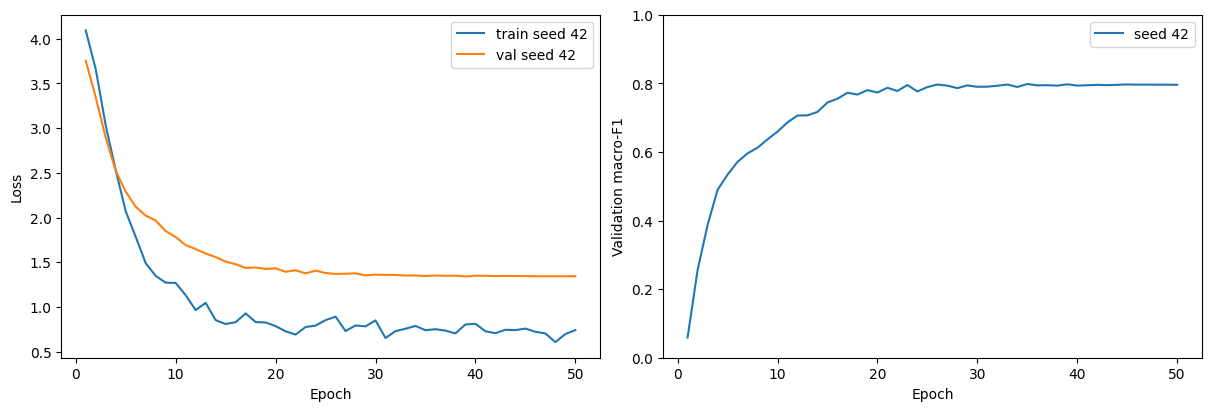

Saved results: /kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16/both_fusion_results.csv
Saved report: /kaggle/working/outputs/mtacs_dtd_split1_ablation_04_both_fusion_vitl16/both_fusion_report.md


,count,valid_captions,valid_rate,class_term_rate
split,,,,
test,1880,1591,0.846277,0.153723
train,1880,1573,0.836702,0.163298
val,1880,1585,0.843085,0.156915


count  valid_captions  valid_rate
role           split                                   
candidate_pool train    376             324    0.861702
query          test    1880            1591    0.846277
               train   1880            1573    0.836702
               val     1880            1585    0.843085

In [14]:
validation_summary = summarize_ablation("val")
test_summary = summarize_ablation("test") if RUN_FINAL_TEST else pd.DataFrame()
status = ablation_run_status()
display(status)
result_tables = [frame.assign(split=name) for name, frame in (("val", validation_summary), ("test", test_summary))
                 if not frame.empty]
results = pd.concat(result_tables, ignore_index=True) if result_tables else pd.DataFrame(
    columns=["experiment", "seed", "split", "epochs_trained", "best_epoch", "accuracy", "macro_f1", "loss"])
results.to_csv(OUT_PUT_DIR / "both_fusion_results.csv", index=False)
display(results.round(4))


def markdown_table(frame):
    if frame.empty:
        return "No completed metrics yet."
    columns = list(frame.columns)
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines += ["| " + " | ".join(str(value).replace("|", "/") for value in row) + " |"
              for row in frame.round(5).fillna("").itertuples(index=False, name=None)]
    return "\n".join(lines)


report = [f"# DTD split {DTD_SPLIT}: both_fusion", "",
          f"Epoch budget: {EPOCHS}; LR schedule horizon: {LR_SCHEDULE_EPOCHS}; early stopping: {EARLY_STOPPING}.",
          "Query image + query caption + one context image + its caption. Both text gates are enabled; selection is image-only.",
          "Same classifier architecture as notebook 01; Florence creates/resumes CSV if needed, then frozen CLIP caches vectors.", "",
          "## Run status", "", markdown_table(status), "", "## Metrics", "", markdown_table(results), "",
          "Candidate pool contains training images only; self-selection is excluded.",
          "Both gates are learned and independently masked for invalid captions. The caption policy is recorded in the protocol.",
          "This is one ablation result, not the comparison of all eight configurations.",
          "Keep split, pool seed, training seed, preprocessing, budget and LR horizon fixed in later notebooks.",
          "Use validation for development; do not select later variants by repeated test-score tuning."]
(OUT_PUT_DIR / "both_fusion_report.md").write_text("\n".join(report) + "\n", encoding="utf-8")

histories = []
for seed in TRAIN_SEEDS:
    path = RUNS_DIR / "both_fusion" / f"seed_{seed}" / "history.csv"
    if path.is_file():
        try:
            history = pd.read_csv(path)
        except pd.errors.EmptyDataError:
            continue
        if not history.empty:
            histories.append((seed, history))
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for seed, history in histories:
        axes[0].plot(history.epoch, history.train_loss, label=f"train seed {seed}")
        axes[0].plot(history.epoch, history.val_loss, label=f"val seed {seed}")
        axes[1].plot(history.epoch, history.val_macro_f1, label=f"seed {seed}")
    axes[0].set_ylabel("Loss")
    axes[1].set_ylabel("Validation macro-F1")
    axes[1].set_ylim(0, 1)
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.legend()
    fig.savefig(OUT_PUT_DIR / "both_fusion_training.png", dpi=160, bbox_inches="tight")
    plt.show()
print("Saved results:", OUT_PUT_DIR / "both_fusion_results.csv")
print("Saved report:", OUT_PUT_DIR / "both_fusion_report.md")

if "audit_summary" in globals():
    display(audit_summary)
    with (OUT_PUT_DIR / "both_fusion_report.md").open("a", encoding="utf-8") as handle:
        handle.write("\n## Screened caption coverage\n\n" + markdown_table(audit_summary.reset_index()) + "\n")

with (OUT_PUT_DIR / "both_fusion_report.md").open("a", encoding="utf-8") as handle:
    handle.write(f"\nCaption input policy: {CAPTION_INPUT_POLICY}. Semantic scores are diagnostic-only for dtd_lexical_v2. Policy changes define different experiments; do not mix their protocols.\n")

if "role_coverage" in globals():
    display(role_coverage)
    with (OUT_PUT_DIR / "both_fusion_report.md").open("a", encoding="utf-8") as handle:
        handle.write("\n## Query and candidate caption coverage\n\n" + markdown_table(role_coverage.reset_index()) + "\n")
